# Behavioral modulation of mouse V1 during natural movies (revised pipeline)

**Question.** Does behavior (running, pupil-linked arousal) modulate V1 mainly through *shared trial-to-trial variability* rather than stimulus tuning, how quickly does it act, and are locomotion and pupil effects separable?

**What changed from the submitted version** (responding to the COSYNE reviews)

| Reviewer concern | Fix in this notebook |
|---|---|
| Not novel / standard model | Separate stimulus-locked vs trial-to-trial residual activity; time-lagged, cross-validated models; unique vs shared variance for running and pupil |
| Pupil may not reflect arousal | Pupil blink cleaning, pupil derivative, and pupil residualized on running |
| Why fine timescale? | Lagged kernels and running-onset-triggered averages |
| Preliminary (1 session) | Loops over all VISp sessions with pupil; statistics at the level of mice |
| Unreadable figures | 300 dpi / vector export, 9-10 pt fonts, colour-blind palette, panel letters |
| Bugs | Stimulus alignment via `timestamps[start]`, correct running/pupil alignment, no silent zero-pupil fallback, standardize before the interaction, CV R² instead of in-sample R² |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
%pip install scipy scikit-learn

In [4]:
import os, sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

rng = np.random.default_rng(0)
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Figure style: readable text, vector-friendly fonts, colour-blind-safe palette (Okabe-Ito)
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 9,
    'axes.labelsize': 10, 'axes.titlesize': 10, 'xtick.labelsize': 9,
    'ytick.labelsize': 9, 'legend.fontsize': 8, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'svg.fonttype': 'none'})
COL = {'run': '#D55E00', 'pupil': '#0072B2', 'both': '#009E73', 'shared': '#999999'}

def panel_label(ax, s):
    ax.text(-0.2, 1.08, s, transform=ax.transAxes, fontsize=13, fontweight='bold')

def save_fig(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.pdf', bbox_inches='tight')   # vector, for submission
    fig.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')   # 300 dpi raster

In [5]:
%pip install allensdk

Note: you may need to restart the kernel to use updated packages.


In [6]:
# SETUP_BOC  -- data access (edit data_root for your machine)
from allensdk.core.brain_observatory_cache import BrainObservatoryCache

data_root = os.environ.get('ABO_ROOT')           # e.g. export ABO_ROOT=/path/to/data
if data_root is None:
    plat = platform.platform()
    if ('Darwin' in plat) or ('macOS' in plat):
        data_root = '/Volumes/TReND2025/'
    elif 'Windows' in plat:
        data_root = 'E:/'
    elif ('amzn' in plat) or ('google.colab' in sys.modules):
        data_root = '/data/'
    else:
        data_root = '/media/$USERNAME/TReND2025/'

manifest_file = os.path.join(data_root, 'allen-brain-observatory/visual-coding-2p/manifest.json')
boc = BrainObservatoryCache(manifest_file=manifest_file)
print('Manifest:', manifest_file)

C:\Users\user\miniconda3\envs\abo\lib\site-packages\allensdk\core\brain_observatory_nwb_data_set.py:43: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Manifest: E:/allen-brain-observatory/visual-coding-2p/manifest.json


## 1. Loading and aligning one session

Allen stimulus tables store `start`/`end` as **imaging-frame indices**, so they index straight into `timestamps` (no division by 30). Running is resampled onto imaging timestamps using its own time base. Pupil blinks are removed rather than silently replaced.

In [7]:
STIM = 'natural_movie_three'
STRUCTURE = 'VISp'

def _interp_valid(t_new, t_old, x):
    x = np.asarray(x, float); ok = np.isfinite(x)
    return np.interp(t_new, np.asarray(t_old)[ok], x[ok])

def smooth(x, win_s, fs):
    k = int(round(win_s * fs))
    return x if k <= 1 else np.convolve(x, np.ones(k) / k, mode='same')

def clean_pupil(area, fs, thr=8.0, pad=3, smooth_s=0.3):
    # remove NaNs, non-positive values and blink-like jumps, then interpolate and smooth
    a = np.asarray(area, float).copy()
    bad = ~np.isfinite(a) | (a <= 0)
    d = np.diff(a, prepend=a[0])
    med = np.nanmedian(d); mad = np.nanmedian(np.abs(d - med)) * 1.4826 + 1e-12
    bad |= np.abs(d - med) > thr * mad
    bad = np.convolve(bad.astype(float), np.ones(2 * pad + 1), mode='same') > 0
    if bad.all():
        raise ValueError('pupil trace unusable')
    idx = np.arange(len(a))
    a[bad] = np.interp(idx[bad], idx[~bad], a[~bad])
    return smooth(a, smooth_s, fs), bad.mean()

def load_session(boc, exp_id, stim=STIM):
    ds = boc.get_ophys_experiment_data(exp_id)
    t, dff = ds.get_dff_traces()                        # dff: (cells, frames)
    dxcm, dxt = ds.get_running_speed()
    run = _interp_valid(t, dxt, dxcm)
    pt, pa = ds.get_pupil_size()                        # raises if no eye tracking -> do NOT fall back to zeros
    fs_p = 1.0 / np.median(np.diff(pt))
    pa_clean, frac_bad = clean_pupil(pa, fs_p)
    pupil = np.interp(t, pt, pa_clean)
    st = ds.get_stimulus_table(stim).copy()
    if 'repeat' not in st.columns:
        st['repeat'] = (st['frame'] == 0).cumsum() - 1
    meta = ds.get_metadata()
    return dict(exp_id=exp_id, t=np.asarray(t), dff=np.asarray(dff), run=run, pupil=pupil,
                stim_table=st, pupil_bad_frac=frac_bad, meta=meta)

def shift1d(x, k):
    # value of x at (t - k); edge-padded
    if k == 0: return x
    out = np.empty_like(x)
    if k > 0: out[k:] = x[:-k]; out[:k] = x[0]
    else:     out[:k] = x[-k:]; out[k:] = x[-1]
    return out

def behavior_features(sess):
    # z-scored behavioral regressors on the imaging time base
    t = sess['t']; fs = 1.0 / np.median(np.diff(t))
    z = lambda x: (x - np.mean(x)) / (np.std(x) + 1e-12)
    run = smooth(sess['run'], 0.2, fs)
    pup = sess['pupil']
    dpup = np.gradient(pup) * fs                         # phasic arousal
    lags = np.arange(0, int(5 * fs), max(1, int(0.5 * fs)))   # 0-5 s of past running
    Xr = np.column_stack([np.ones(len(run))] + [shift1d(run, k) for k in lags])
    beta = np.linalg.lstsq(Xr, pup, rcond=None)[0]
    pres = pup - Xr @ beta                               # pupil not explained by running
    return dict(run=z(run), pupil=z(pup), dpupil=z(smooth(dpup, 0.3, fs)), pupil_resid=z(pres)), fs

## 2. Movie-aligned tensors, stimulus-locked vs residual activity

Each movie repeat gives the same stimulus. The **leave-one-repeat-out mean** is the stimulus-locked prediction; what is left is trial-to-trial variability, which is where behavior should act if it is not just a stimulus effect.

In [8]:
def shift2d(B, k):
    # shift along the frame axis within each repeat (never across repeats)
    if k == 0: return B
    out = np.empty_like(B)
    if k > 0: out[:, k:] = B[:, :-k]; out[:, :k] = B[:, [0]]
    else:     out[:, :k] = B[:, -k:]; out[:, k:] = B[:, [-1]]
    return out

def build_tensors(sess, feats):
    st = sess['stim_table']
    reps = np.sort(st['repeat'].unique()); frames = np.sort(st['frame'].unique())
    idx = np.full((len(reps), len(frames)), -1, dtype=int)
    idx[np.searchsorted(reps, st['repeat'].values),
        np.searchsorted(frames, st['frame'].values)] = st['start'].values.astype(int)
    ok = idx >= 0
    Y = np.full((sess['dff'].shape[0],) + idx.shape, np.nan)
    Y[:, ok] = sess['dff'][:, idx[ok]]
    B = {}
    for name, x in feats.items():
        b = np.full(idx.shape, np.nan); b[ok] = x[idx[ok]]; B[name] = b
    return Y, B, ok

LAGS = (-15, 0, 8, 15, 30, 60)      # frames (~ -0.5 s to +2 s of past behaviour); negative = future (a sanity check)

MODEL_SETS = {
    'run':        dict(names=['run'], interaction=False),
    'pupil':      dict(names=['pupil', 'dpupil'], interaction=False),
    'run+pupilR': dict(names=['run', 'pupil_resid'], interaction=False),   # arousal beyond running
    'both':       dict(names=['run', 'pupil', 'dpupil'], interaction=True),
}

def make_design(B, names, interaction, lags=LAGS):
    cols = [shift2d(B[n], k) for n in names for k in lags]
    if interaction:
        cols.append(B['run'] * B['pupil'])    # product of two z-scored variables
    return np.stack(cols, axis=-1)            # (repeat, frame, p)

def cv_r2(R, X, groups, alpha=100.0, n_splits=5):
    # cross-validated R2 per output column; folds hold out whole movie repeats
    n_splits = min(n_splits, len(np.unique(groups)))
    pred = np.zeros_like(R)
    for tr, te in GroupKFold(n_splits).split(X, groups=groups):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        m = Ridge(alpha=alpha).fit((X[tr] - mu) / sd, R[tr])
        pred[te] = m.predict((X[te] - mu) / sd)
    sse = ((R - pred) ** 2).sum(0); sst = ((R - R.mean(0)) ** 2).sum(0)
    return 1 - sse / sst

def circ_null(R, X, groups, n_perm=50, min_shift=300, alpha=100.0):
    # circularly shift behaviour relative to neural data: keeps behaviour autocorrelation, breaks the pairing
    out = []
    N = len(R)
    for _ in range(n_perm):
        k = rng.integers(min_shift, N - min_shift)
        out.append(np.median(cv_r2(R, np.roll(X, k, axis=0), groups, alpha)))
    return np.array(out)

## 3. Full single-session analysis

In [9]:
def analyze(sess, n_perm=50, n_pc=10, alpha=100.0):
    feats, fs = behavior_features(sess)
    Y, B, ok = build_tensors(sess, feats)
    n_cells, n_rep, n_fr = Y.shape
    if n_rep < 3: raise ValueError('need >= 3 movie repeats')

    # stimulus-locked prediction = mean of the OTHER repeats
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo

    valid = ok & np.isfinite(Yres).all(0)
    for b in B.values(): valid &= np.isfinite(b)
    groups = np.broadcast_to(np.arange(n_rep)[:, None], (n_rep, n_fr))[valid]

    Ytot = Y[:, valid].T; Rraw = Yres[:, valid].T
    sst_tot = ((Ytot - Ytot.mean(0)) ** 2).sum(0)
    sst_res = ((Rraw - Rraw.mean(0)) ** 2).sum(0)
    R = (Rraw - Rraw.mean(0)) / (Rraw.std(0) + 1e-9)

    designs = {k: make_design(B, v['names'], v['interaction'])[valid] for k, v in MODEL_SETS.items()}
    r2 = {k: cv_r2(R, X, groups, alpha) for k, X in designs.items()}

    cells = pd.DataFrame({
        'r2_run': r2['run'], 'r2_pupil': r2['pupil'], 'r2_both': r2['both'],
        'r2_run+pupilR': r2['run+pupilR'],
        'uniq_run': r2['both'] - r2['pupil'],
        'uniq_pupil': r2['both'] - r2['run'],
        'shared': r2['run'] + r2['pupil'] - r2['both'],
        'arousal_beyond_run': r2['run+pupilR'] - r2['run'],
        'stim_locked_frac': 1 - sst_res / sst_tot,          # fraction of total variance that repeats with the movie
        'behav_frac_of_total': r2['both'] * sst_res / sst_tot})   # behaviour share of TOTAL variance

    null = circ_null(R, designs['both'], groups, n_perm, alpha=alpha)
    obs = np.median(r2['both'])
    p_null = (1 + (null >= obs).sum()) / (n_perm + 1)

    # population level: PCA on trial-to-trial residuals
    pca = PCA(n_components=min(n_pc, R.shape[1])).fit(R)
    scores = pca.transform(R)
    r2_pc = cv_r2(scores, designs['both'], groups, alpha)
    pc = pd.DataFrame({'PC': np.arange(1, len(r2_pc) + 1),
                       'pct_pop_var': pca.explained_variance_ratio_ * 100,
                       'behav_R2_of_PC': r2_pc,
                       'behav_share_of_pop_var_pct': pca.explained_variance_ratio_ * r2_pc * 100})

    # behaviour axis (running, lag 0) and its overlap with the stimulus-locked subspace
    lag0 = list(LAGS).index(0)
    Xrun = designs['run']
    axis = Ridge(alpha=alpha).fit((Xrun - Xrun.mean(0)) / (Xrun.std(0) + 1e-9), R).coef_[:, lag0]
    axis = axis / (np.linalg.norm(axis) + 1e-12)
    stim_mean = np.nanmean(Y, axis=1).T                     # (frames, cells)
    stim_mean = (stim_mean - stim_mean.mean(0)) / (stim_mean.std(0) + 1e-9)
    stim_pcs = PCA(n_components=n_pc).fit(np.nan_to_num(stim_mean)).components_      # (n_pc, cells)
    overlap = np.linalg.norm(stim_pcs @ axis) ** 2
    chance = n_pc / R.shape[1]

    return dict(cells=cells, pc=pc, null=null, p_null=p_null, feats=feats, fs=fs,
                total_pop_behav_frac=float(cells['behav_frac_of_total'].mean()),
                axis_stim_overlap=float(overlap), axis_overlap_chance=float(chance),
                n_cells=n_cells, n_rep=n_rep)

In [12]:
# ===== PATCH: robust pupil/running handling + safer CV. Run this cell AFTER all the earlier definition cells,
# ===== then re-run the cell that calls analyze() and everything after it.
MIN_VALID = 5000          # minimum usable frames per session (about 170 s)
DROP_FIRST_S = 10         # drop the start-up transient
RUN_THR = 3.0             # cm/s, used for "mouse is running" bookkeeping and onsets
MIN_FRAC_RUN = 0.01       # skip sessions where the mouse runs < 1% of usable frames

def smooth(x, win_s, fs):
    # NaN-aware centred moving average
    k = int(round(win_s * fs))
    if k <= 1: return np.asarray(x, float)
    return pd.Series(x).rolling(k, center=True, min_periods=1).mean().to_numpy()

def fill_short_gaps(a, max_gap):
    # linearly fill NaN runs of length <= max_gap samples; LONG gaps stay NaN (never invent data)
    a = np.asarray(a, float).copy()
    isn = ~np.isfinite(a)
    if not isn.any(): return a
    idx = np.arange(len(a))
    edges = np.diff(np.r_[0, isn.astype(int), 0])
    for s, e in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
        if (e - s) <= max_gap and s > 0 and e < len(a):
            a[s:e] = np.interp(idx[s:e], [s - 1, e], [a[s - 1], a[e]])
    return a

def clean_pupil(area, fs, max_gap_s=0.5):
    a = np.asarray(area, float).copy()
    a[a <= 0] = np.nan
    lo, hi = np.nanpercentile(a, [1, 99])
    a = np.clip(a, lo, hi)                      # tame the heavy tail
    a = fill_short_gaps(a, int(max_gap_s * fs))
    return a, float(np.mean(~np.isfinite(a)))   # fraction still missing

def load_session(boc, exp_id, stim=STIM):
    ds = boc.get_ophys_experiment_data(exp_id)
    t, dff = ds.get_dff_traces()
    dxcm, dxt = ds.get_running_speed()
    run = _interp_valid(t, dxt, dxcm)
    pt, pa = ds.get_pupil_size()
    fs_p = 1.0 / np.median(np.diff(pt))
    pa_clean, frac_missing = clean_pupil(pa, fs_p)
    pupil = np.interp(t, pt, pa_clean)          # stays NaN wherever the pupil is missing
    st = ds.get_stimulus_table(stim).copy()
    if 'repeat' not in st.columns:
        st['repeat'] = (st['frame'] == 0).cumsum() - 1
    return dict(exp_id=exp_id, t=np.asarray(t), dff=np.asarray(dff), run=run, pupil=pupil,
                stim_table=st, pupil_bad_frac=frac_missing, meta=ds.get_metadata())

def behavior_features(sess):
    t = sess['t']; fs = 1.0 / np.median(np.diff(t))
    zs = lambda x: np.clip((x - np.nanmean(x)) / (np.nanstd(x) + 1e-12), -5, 5)
    spd = smooth(sess['run'], 0.2, fs)
    run = np.log1p(np.clip(spd, 0, None))       # log tames the very skewed running distribution
    pup = sess['pupil']
    dpup = np.gradient(pup) * fs                # NaN near gaps -> those frames get excluded
    lags = np.arange(0, int(5 * fs), max(1, int(0.5 * fs)))
    Xr = np.column_stack([np.ones(len(spd))] + [shift1d(spd, k) for k in lags])
    ok = np.isfinite(pup)
    beta = np.linalg.lstsq(Xr[ok], pup[ok], rcond=None)[0]
    pres = pup - Xr @ beta                      # pupil not explained by running (NaN where pupil missing)
    return dict(run=zs(run), pupil=zs(pup), dpupil=zs(smooth(dpup, 0.3, fs)),
                pupil_resid=zs(pres), _t=t - t[0]), fs

def cv_r2(R, X, groups, alpha=1e4, n_splits=5):
    n_splits = min(n_splits, len(np.unique(groups)))
    pred = np.zeros_like(R)
    for tr, te in GroupKFold(n_splits).split(X, groups=groups):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        Xtr = np.clip((X[tr] - mu) / sd, -5, 5); Xte = np.clip((X[te] - mu) / sd, -5, 5)
        pred[te] = Ridge(alpha=alpha).fit(Xtr, R[tr]).predict(Xte)
    sse = ((R - pred) ** 2).sum(0); sst = ((R - R.mean(0)) ** 2).sum(0)
    return 1 - sse / sst

def circ_null(R, X, groups, n_perm=50, min_shift=300, alpha=1e4):
    N = len(R); out = []
    for _ in range(n_perm):
        k = rng.integers(min_shift, N - min_shift)
        out.append(np.median(cv_r2(R, np.roll(X, k, axis=0), groups, alpha)))
    return np.array(out)

def analyze(sess, n_perm=50, n_pc=10, alpha=1e4):
    feats, fs = behavior_features(sess)
    Y, B, ok = build_tensors(sess, feats)
    n_cells, n_rep, n_fr = Y.shape
    if n_rep < 3: raise ValueError('need >= 3 movie repeats')
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo

    designs_full = {k: make_design(B, v['names'], v['interaction']) for k, v in MODEL_SETS.items()}
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S)
    for D in designs_full.values():
        valid &= np.isfinite(D).all(-1)          # excludes frames with missing pupil (incl. lagged)
    if valid.sum() < MIN_VALID:
        raise ValueError(f'only {valid.sum()} usable frames (pupil missing?)')
    frac_run = float(np.mean(_run_at(sess, ok)[valid] > RUN_THR))
    if frac_run < MIN_FRAC_RUN:
        raise ValueError(f'mouse ran only {100*frac_run:.2f}% of usable frames')

    groups = np.broadcast_to(np.arange(n_rep)[:, None], (n_rep, n_fr))[valid]
    Ytot = Y[:, valid].T; Rraw = Yres[:, valid].T
    sst_tot = ((Ytot - Ytot.mean(0)) ** 2).sum(0)
    sst_res = ((Rraw - Rraw.mean(0)) ** 2).sum(0)
    R = (Rraw - Rraw.mean(0)) / (Rraw.std(0) + 1e-9)

    designs = {k: D[valid] for k, D in designs_full.items()}
    r2 = {k: cv_r2(R, X, groups, alpha) for k, X in designs.items()}
    cells = pd.DataFrame({
        'r2_run': r2['run'], 'r2_pupil': r2['pupil'], 'r2_both': r2['both'], 'r2_run+pupilR': r2['run+pupilR'],
        'uniq_run': r2['both'] - r2['pupil'], 'uniq_pupil': r2['both'] - r2['run'],
        'shared': r2['run'] + r2['pupil'] - r2['both'],
        'arousal_beyond_run': r2['run+pupilR'] - r2['run'],
        'stim_locked_frac': 1 - sst_res / sst_tot,
        'behav_frac_of_total': np.clip(r2['both'], 0, None) * sst_res / sst_tot})   # floored at 0

    null = circ_null(R, designs['both'], groups, n_perm, alpha=alpha)
    obs = np.median(r2['both']); p_null = (1 + (null >= obs).sum()) / (n_perm + 1)

    n_pc = int(min(n_pc, R.shape[1] - 1, R.shape[0] - 1))
    pca = PCA(n_components=n_pc).fit(R); scores = pca.transform(R)
    r2_pc = cv_r2(scores, designs['both'], groups, alpha)
    pc = pd.DataFrame({'PC': np.arange(1, n_pc + 1), 'pct_pop_var': pca.explained_variance_ratio_ * 100,
                       'behav_R2_of_PC': r2_pc,
                       'behav_share_of_pop_var_pct': pca.explained_variance_ratio_ * np.clip(r2_pc, 0, None) * 100})

    lag0 = list(LAGS).index(0); Xrun = designs['run']
    axis = Ridge(alpha=alpha).fit(np.clip((Xrun - Xrun.mean(0)) / (Xrun.std(0) + 1e-9), -5, 5), R).coef_[:, lag0]
    axis = axis / (np.linalg.norm(axis) + 1e-12)
    stim_mean = np.nanmean(Y, axis=1).T
    stim_mean = (stim_mean - stim_mean.mean(0)) / (stim_mean.std(0) + 1e-9)
    k_s = int(min(n_pc, stim_mean.shape[1] - 1))
    stim_pcs = PCA(n_components=k_s).fit(np.nan_to_num(stim_mean)).components_
    return dict(cells=cells, pc=pc, null=null, p_null=p_null, feats=feats, fs=fs,
                total_pop_behav_frac=float(cells['behav_frac_of_total'].mean()),
                axis_stim_overlap=float(np.linalg.norm(stim_pcs @ axis) ** 2),
                axis_overlap_chance=float(k_s / R.shape[1]),
                n_cells=n_cells, n_rep=n_rep, n_valid=int(valid.sum()), frac_run=frac_run)

def _run_at(sess, ok):
    # raw running speed (cm/s) laid out on the (repeat, frame) grid
    st = sess['stim_table']
    reps = np.sort(st['repeat'].unique()); frames = np.sort(st['frame'].unique())
    idx = np.full(ok.shape, -1, dtype=int)
    idx[np.searchsorted(reps, st['repeat'].values), np.searchsorted(frames, st['frame'].values)] = st['start'].values.astype(int)
    out = np.full(ok.shape, np.nan); out[ok] = sess['run'][idx[ok]]
    return out

def find_run_onsets(run_raw, fs, thr=RUN_THR, quiet_thr=1.0, quiet_s=2.0, sustain_s=1.0, min_gap_s=5.0):
    # a real onset: quiet for 2 s, then speed > 3 cm/s sustained for 1 s
    spd = smooth(run_raw, 0.2, fs); q = int(quiet_s * fs); su = int(sustain_s * fs); gap = int(min_gap_s * fs)
    onsets, last = [], -10 ** 9
    for i in range(q, len(spd) - su):
        if spd[i] > thr and spd[i:i + su].min() > quiet_thr * 2 and (spd[i - q:i] < quiet_thr).all() and i - last >= gap:
            onsets.append(i); last = i
    return np.array(onsets, dtype=int)

def fig_onset(sess, res, pre_s=2, post_s=6):
    fs = res['fs']; pre, post = int(pre_s * fs), int(post_s * fs)
    on = find_run_onsets(sess['run'], fs)
    z = lambda x: (x - x.mean(0)) / (x.std(0) + 1e-9)
    pop = z(sess['dff'].T).mean(1)
    tau = np.arange(-pre, post) / fs
    fig, ax = plt.subplots(1, 3, figsize=(9.5, 2.9))
    for a, x, col, lab in zip(ax, [sess['run'], pop, res['feats']['pupil']], [COL['run'], 'k', COL['pupil']],
                              ['Running speed (cm/s)', 'Population ΔF/F (z)', 'Pupil area (z)']):
        E = event_triggered(x, on, pre, post)
        if len(E) == 0: continue
        m = np.nanmean(E, 0); s = np.nanstd(E, 0) / np.sqrt(np.sum(np.isfinite(E), 0).clip(1))
        a.plot(tau, m, color=col); a.fill_between(tau, m - s, m + s, color=col, alpha=0.25)
        a.axvline(0, color='k', lw=0.5, ls='--'); a.set_xlabel('Time from running onset (s)'); a.set_ylabel(lab)
    ax[1].set_title(f'n = {len(on)} onsets')
    for a, l in zip(ax, 'ABC'): panel_label(a, l)
    fig.tight_layout(); return fig

print('patch loaded')

patch loaded


In [13]:
EXP_ID = 528402271         # the session from the original analysis; swap for any experiment id with pupil data
sess = load_session(boc, EXP_ID)
res = analyze(sess)

c = res['cells']
print(f"{res['n_cells']} cells, {res['n_rep']} movie repeats, {100*sess['pupil_bad_frac']:.1f}% pupil samples interpolated")
print(f"Median CV R2 (behaviour -> residuals):  run {c.r2_run.median():.3f} | pupil {c.r2_pupil.median():.3f} | both {c.r2_both.median():.3f}")
print(f"Shuffle null for 'both' (median over cells): {np.median(res['null']):.3f}, p = {res['p_null']:.3f}")
print(f"Unique run {c.uniq_run.median():.3f} | unique pupil {c.uniq_pupil.median():.3f} | shared {c.shared.median():.3f}")
print(f"Share of TOTAL variance explained by behaviour (mean over cells): {100*res['total_pop_behav_frac']:.2f}%")
print(f"Behaviour axis lies {100*res['axis_stim_overlap']:.1f}% in the stimulus subspace (chance {100*res['axis_overlap_chance']:.1f}%)")
res['pc'].round(3)

209 cells, 10 movie repeats, 47.9% pupil samples interpolated
Median CV R2 (behaviour -> residuals):  run -0.006 | pupil -0.006 | both -0.007
Shuffle null for 'both' (median over cells): -0.007, p = 0.569
Unique run -0.000 | unique pupil -0.001 | shared -0.005
Share of TOTAL variance explained by behaviour (mean over cells): 0.15%
Behaviour axis lies 10.9% in the stimulus subspace (chance 4.8%)


,PC,pct_pop_var,behav_R2_of_PC,behav_share_of_pop_var_pct
0,1,2.632,0.005,0.014
1,2,1.348,0.100,0.134
2,3,1.287,-0.177,0.000
3,4,1.267,-0.091,0.000
4,5,1.228,-0.025,0.000
5,6,1.147,-0.023,0.000
6,7,1.098,-0.076,0.000
7,8,1.029,-0.023,0.000
8,9,1.007,-0.060,0.000
9,10,0.982,-0.030,0.000


**Reading the PC table.** `behav_R2_of_PC` is how much of *that PC's* variance behavior explains (this is what the original abstract called "22% variance"). `behav_share_of_pop_var_pct` is that value multiplied by the PC's share of population variance, i.e. how much of the whole population variance behavior actually explains through that PC. Report the second number when making population-level claims.

## 4. Figures (vector PDF + 300 dpi PNG saved to `figures/`)

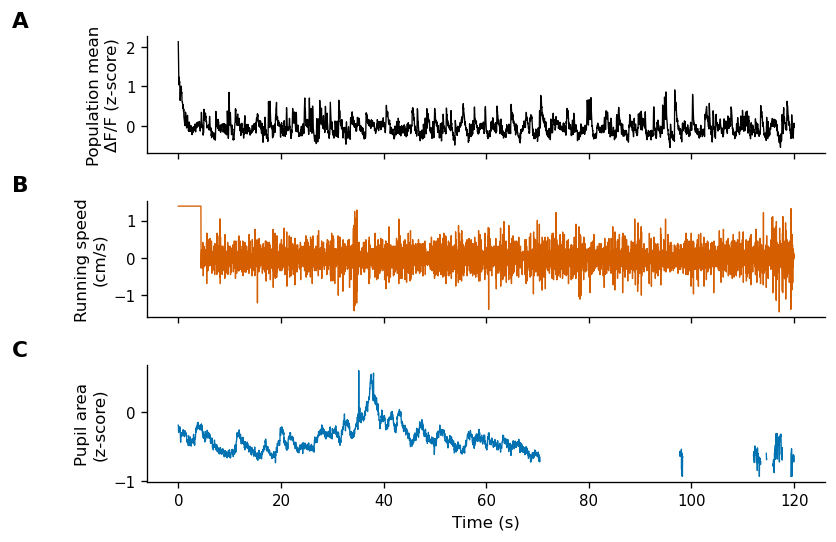

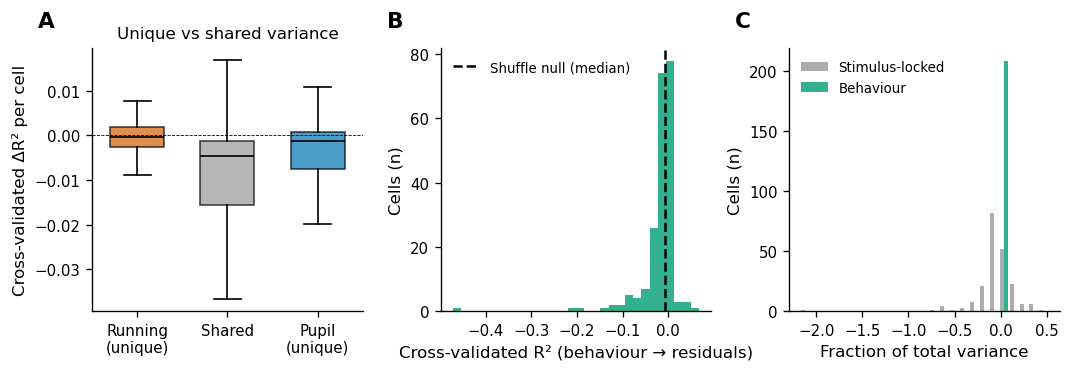

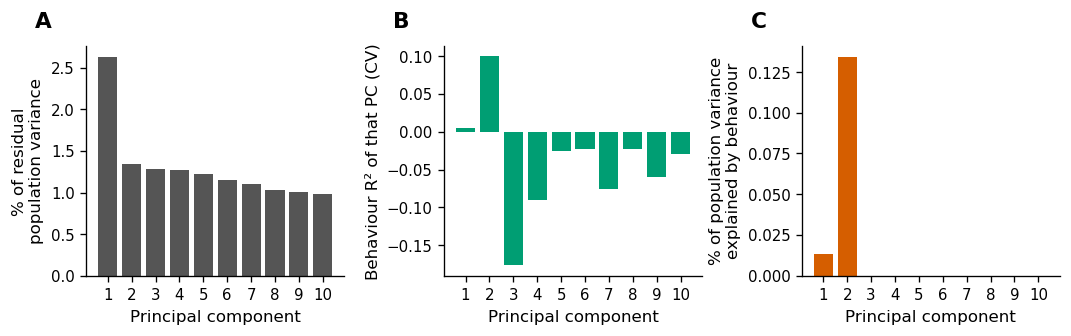

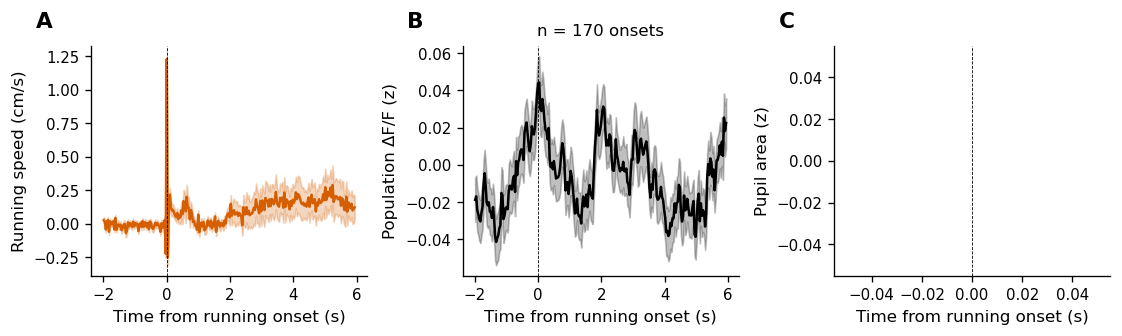

In [14]:
def fig_traces(sess, res, t0=0, dur=120):
    t = sess['t']; m = (t >= t0 + t[0]) & (t < t0 + t[0] + dur)
    tt = t[m] - t[m][0]
    z = lambda x: (x - x.mean(0)) / (x.std(0) + 1e-9)
    pop = z(sess['dff'].T).mean(1)
    fig, ax = plt.subplots(3, 1, figsize=(7, 4.6), sharex=True)
    ax[0].plot(tt, pop[m], color='k', lw=0.8); ax[0].set_ylabel('Population mean\nΔF/F (z-score)')
    ax[1].plot(tt, sess['run'][m], color=COL['run'], lw=0.8); ax[1].set_ylabel('Running speed\n(cm/s)')
    ax[2].plot(tt, res['feats']['pupil'][m], color=COL['pupil'], lw=0.8); ax[2].set_ylabel('Pupil area\n(z-score)')
    ax[2].set_xlabel('Time (s)')
    for a, l in zip(ax, 'ABC'): panel_label(a, l)
    fig.tight_layout(); return fig

def fig_variance(res):
    c = res['cells']
    fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
    data = [c.uniq_run, c.shared, c.uniq_pupil]
    bp = ax[0].boxplot(data, widths=0.6, patch_artist=True, showfliers=False)
    for patch, col in zip(bp['boxes'], [COL['run'], COL['shared'], COL['pupil']]):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    for med in bp['medians']: med.set_color('k')
    ax[0].axhline(0, color='k', lw=0.5, ls='--')
    ax[0].set_xticks([1, 2, 3]); ax[0].set_xticklabels(['Running\n(unique)', 'Shared', 'Pupil\n(unique)'])
    ax[0].set_ylabel('Cross-validated ΔR² per cell'); ax[0].set_title('Unique vs shared variance')
    ax[1].hist(c.r2_both, bins=30, color=COL['both'], alpha=0.8)
    ax[1].axvline(np.median(res['null']), color='k', ls='--', label='Shuffle null (median)')
    ax[1].set_xlabel('Cross-validated R² (behaviour → residuals)'); ax[1].set_ylabel('Cells (n)'); ax[1].legend()
    ax[2].hist([c.stim_locked_frac, c.behav_frac_of_total], bins=25, label=['Stimulus-locked', 'Behaviour'],
               color=['#999999', COL['both']], alpha=0.8)
    ax[2].set_xlabel('Fraction of total variance'); ax[2].set_ylabel('Cells (n)'); ax[2].legend()
    for a, l in zip(ax, 'ABC'): panel_label(a, l)
    fig.tight_layout(); return fig

def fig_pcs(res):
    pc = res['pc']
    fig, ax = plt.subplots(1, 3, figsize=(9, 2.9))
    ax[0].bar(pc.PC, pc.pct_pop_var, color='#555555'); ax[0].set_ylabel('% of residual\npopulation variance')
    ax[1].bar(pc.PC, pc.behav_R2_of_PC, color=COL['both']); ax[1].set_ylabel('Behaviour R² of that PC (CV)')
    ax[2].bar(pc.PC, pc.behav_share_of_pop_var_pct, color=COL['run']); ax[2].set_ylabel('% of population variance\nexplained by behaviour')
    for a, l in zip(ax, 'ABC'): a.set_xlabel('Principal component'); a.set_xticks(pc.PC); panel_label(a, l)
    fig.tight_layout(); return fig

def find_run_onsets(run_raw, fs, thr=1.0, quiet_s=2.0, min_gap_s=5.0):
    moving = run_raw > thr; q = int(quiet_s * fs); gap = int(min_gap_s * fs)
    onsets, last = [], -10 ** 9
    for i in range(q, len(moving)):
        if moving[i] and not moving[i - q:i].any() and i - last >= gap:
            onsets.append(i); last = i
    return np.array(onsets, dtype=int)

def event_triggered(x, onsets, pre, post):
    segs = [x[o - pre:o + post] for o in onsets if o - pre >= 0 and o + post <= len(x)]
    return np.array(segs)

def fig_onset(sess, res, pre_s=2, post_s=6):
    fs = res['fs']; pre, post = int(pre_s * fs), int(post_s * fs)
    on = find_run_onsets(sess['run'], fs)
    z = lambda x: (x - x.mean(0)) / (x.std(0) + 1e-9)
    pop = z(sess['dff'].T).mean(1)
    tau = np.arange(-pre, post) / fs
    fig, ax = plt.subplots(1, 3, figsize=(9.5, 2.9))
    for a, x, col, lab in zip(ax, [sess['run'], pop, res['feats']['pupil']],
                              [COL['run'], 'k', COL['pupil']],
                              ['Running speed (cm/s)', 'Population ΔF/F (z)', 'Pupil area (z)']):
        E = event_triggered(x, on, pre, post)
        if len(E) == 0: continue
        m, s = E.mean(0), E.std(0) / np.sqrt(len(E))
        a.plot(tau, m, color=col); a.fill_between(tau, m - s, m + s, color=col, alpha=0.25)
        a.axvline(0, color='k', lw=0.5, ls='--'); a.set_xlabel('Time from running onset (s)'); a.set_ylabel(lab)
    ax[1].set_title(f'n = {len(on)} onsets')
    for a, l in zip(ax, 'ABC'): panel_label(a, l)
    fig.tight_layout(); return fig

for name, f in [('fig1_traces', fig_traces(sess, res)), ('fig2_variance', fig_variance(res)),
                ('fig3_pcs', fig_pcs(res)), ('fig4_onset', fig_onset(sess, res))]:
    save_fig(f, name); plt.show()

## 5. All VISp sessions with pupil data — statistics at the level of mice

Cached to `session_summary.csv` so the slow loop only runs once. Sessions from the same mouse are averaged before testing, so mice (not sessions or cells) are the unit of replication.

In [15]:
def list_sessions(boc, structure=STRUCTURE, stim=STIM):
    exps = boc.get_ophys_experiments(targeted_structures=[structure], stimuli=[stim])
    return pd.DataFrame(exps)

def summarize(boc, row, n_perm=30):
    sess = load_session(boc, row['id'])
    r = analyze(sess, n_perm=n_perm)
    c = r['cells']
    return dict(exp_id=row['id'], mouse=row.get('donor_name'), cre_line=row.get('cre_line'),
                depth=row.get('imaging_depth'), n_cells=r['n_cells'],
                r2_run=c.r2_run.median(), r2_pupil=c.r2_pupil.median(), r2_both=c.r2_both.median(),
                uniq_run=c.uniq_run.median(), uniq_pupil=c.uniq_pupil.median(), shared=c.shared.median(),
                arousal_beyond_run=c.arousal_beyond_run.median(),
                behav_frac_of_total=r['total_pop_behav_frac'], p_null=r['p_null'],
                axis_stim_overlap=r['axis_stim_overlap'])

SUMMARY_CSV = 'session_summary.csv'
if os.path.exists(SUMMARY_CSV):
    summary = pd.read_csv(SUMMARY_CSV)
else:
    sessions = list_sessions(boc); rows = []
    for _, row in sessions.iterrows():
        try:
            rows.append(summarize(boc, row)); print('done', row['id'])
        except Exception as e:                      # no pupil / too few repeats: skip but SAY so
            print('skipped', row['id'], '->', repr(e))
    summary = pd.DataFrame(rows); summary.to_csv(SUMMARY_CSV, index=False)
print(len(summary), 'sessions,', summary['mouse'].nunique(), 'mice')
summary.round(3).head()

skipped 704298735 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 663479824 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 662033243 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 545446482 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 510214538 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 546716391 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 649401936 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 662361096 -> NoEyeTrackingException('No pupil tracking for this experiment.')
done 528402271
skipped 657078119 -> NoEyeTrackingException('No pupil tracking for this experiment.')
done 581150104
skipped 644026238 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 503109347 -> NoEyeTrackingException('No pupil tracking for this experiment.')
skipped 643645390 -> NoE

,exp_id,mouse,cre_line,depth,n_cells,r2_run,r2_pupil,r2_both,uniq_run,uniq_pupil,shared,arousal_beyond_run,behav_frac_of_total,p_null,axis_stim_overlap
0,528402271,237706,Emx1-IRES-Cre,275,209,-0.006,-0.006,-0.007,-0.000,-0.001,-0.005,-0.001,0.002,0.710,0.109
1,581150104,296462,Sst-IRES-Cre,275,8,0.002,-0.000,0.005,0.003,0.002,-0.002,0.001,0.007,0.032,0.999
2,502962794,226219,Rbp4-Cre_KL100,375,79,-0.002,-0.003,-0.002,-0.000,-0.000,-0.003,-0.000,0.001,0.032,0.204
3,571137446,288600,Rbp4-Cre_KL100,375,48,-0.000,-0.001,-0.000,0.000,0.000,-0.000,0.000,0.002,0.032,0.340
4,577379202,296891,Sst-IRES-Cre,375,6,-0.001,-0.007,-0.006,0.000,-0.003,-0.004,-0.002,0.000,0.387,0.999


Unique running vs unique pupil across mice (n=10): Wilcoxon p = 0.193
Arousal beyond running: median -0.0000, Wilcoxon vs 0 p = 0.557


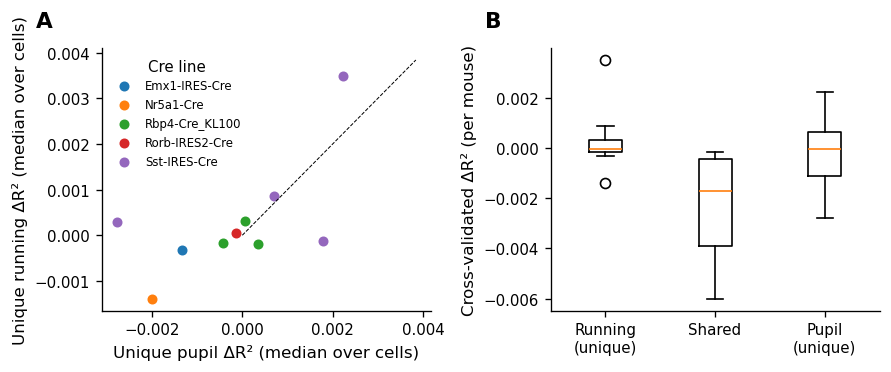

In [16]:
by_mouse = summary.groupby('mouse')[['uniq_run', 'uniq_pupil', 'shared', 'arousal_beyond_run', 'behav_frac_of_total']].mean()
w = stats.wilcoxon(by_mouse.uniq_run, by_mouse.uniq_pupil)
print(f'Unique running vs unique pupil across mice (n={len(by_mouse)}): Wilcoxon p = {w.pvalue:.3g}')
print(f'Arousal beyond running: median {by_mouse.arousal_beyond_run.median():.4f}, '
      f'Wilcoxon vs 0 p = {stats.wilcoxon(by_mouse.arousal_beyond_run).pvalue:.3g}')

fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.2))
lim = max(summary.uniq_run.max(), summary.uniq_pupil.max()) * 1.1
ax[0].plot([0, lim], [0, lim], 'k--', lw=0.6)
for cre, g in summary.groupby('cre_line'):
    ax[0].scatter(g.uniq_pupil, g.uniq_run, s=25, label=cre)
ax[0].set_xlabel('Unique pupil ΔR² (median over cells)'); ax[0].set_ylabel('Unique running ΔR² (median over cells)')
ax[0].legend(title='Cre line', fontsize=7)
ax[1].boxplot([by_mouse.uniq_run, by_mouse.shared, by_mouse.uniq_pupil], showfliers=True)
ax[1].set_xticks([1, 2, 3]); ax[1].set_xticklabels(['Running\n(unique)', 'Shared', 'Pupil\n(unique)'])
ax[1].set_ylabel('Cross-validated ΔR² (per mouse)')
for a, l in zip(ax, 'AB'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig5_sessions'); plt.show()

## 6. Suggested next steps / things to check before resubmitting

- **Compare areas** (`STRUCTURE = 'VISal'`, `'VISl'`, ...) with the same pipeline. The old VISal comparison cell was a copy of the VISp table, so redo it from scratch.
- **Layer / Cre-line effects:** `summary` already has `cre_line` and `depth`.
- **Deconvolved events** instead of ΔF/F would sharpen the lag analysis (calcium kinetics blur timing).
- **Eye movements:** add `ds.get_pupil_location()` speed as a nuisance regressor.
- **Alpha:** `Ridge(alpha=100)` is a fixed choice; nest a CV over alpha if a reviewer asks.
- **Literature framing:** Niell & Stryker 2010; McGinley et al. 2015; Vinck et al. 2015; Stringer et al. 2019; Musall et al. 2019; Dipoppa et al. 2018. State clearly what is new (e.g., variance partitioning of running vs pupil in *natural-movie* residuals, with lags, across mice).
- Figure captions need: n (cells / sessions / mice), what the model was, what error bars or shading mean.

=== RUNNING ===
NaN fraction in raw running: 0.003
Percentiles (cm/s) 1/50/90/99/max: [-9.500e-01  1.000e-02  3.800e-01  1.718e+01  2.653e+01]
Fraction of frames > 1 cm/s:  all 0.031 | during movie 0.053
Fraction of frames > 3 cm/s:  all 0.021 | during movie 0.043
Fraction of frames > 5 cm/s:  all 0.020 | during movie 0.040
Fraction negative (< -0.5 cm/s): 0.038

=== PUPIL ===
Samples: 115728, sampling rate ~30.1 Hz
NaN fraction: 0.510 | <=0 fraction: 0.000
Percentiles 1/50/99: [ 2851.2  3950.4 12495.3]
Frames flagged at 8x MAD (before padding): 0.536
Frames flagged at 15x MAD (before padding): 0.526
Frames flagged at 30x MAD (before padding): 0.522
Frames flagged at 60x MAD (before padding): 0.520
Fraction interpolated in the notebook run: 0.479


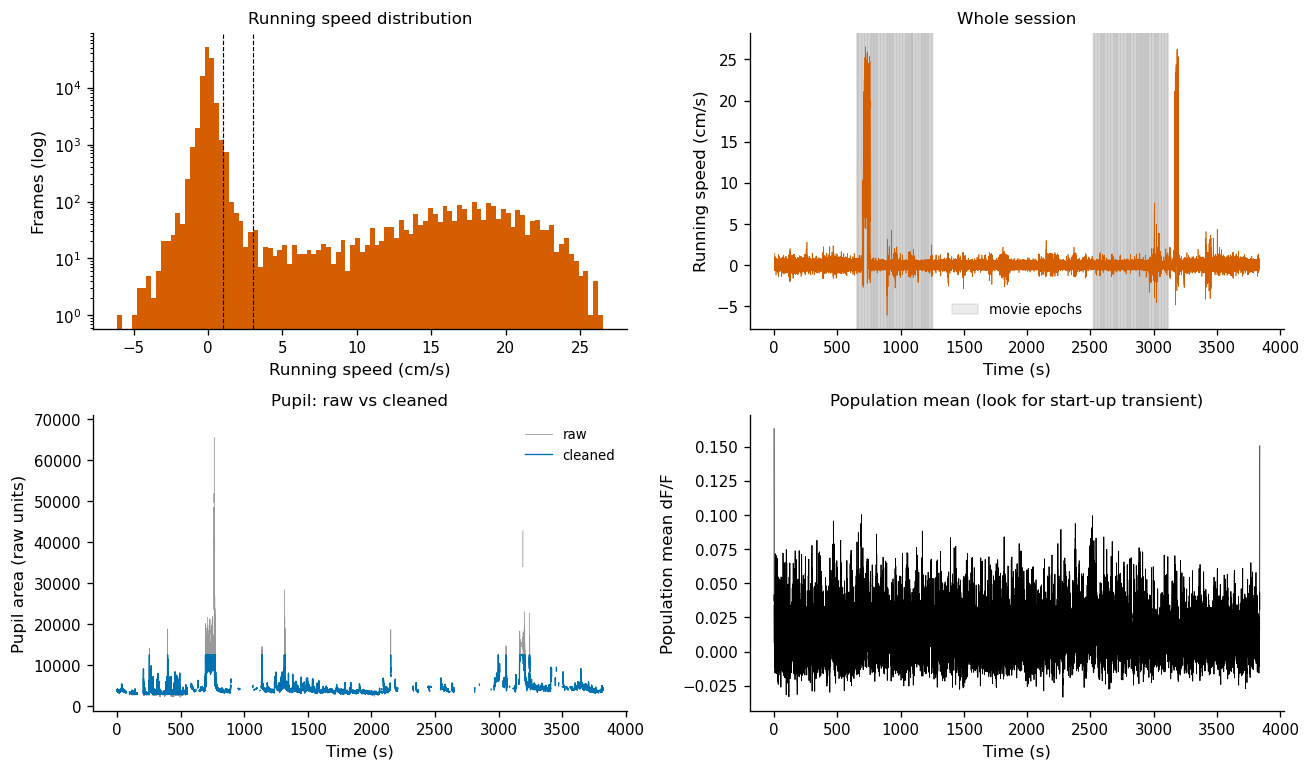

In [17]:
# ---- DIAGNOSTIC: is there real running, and is the pupil trace sane? ----
ds = boc.get_ophys_experiment_data(EXP_ID)
t, _ = ds.get_dff_traces()
dxcm, dxt = ds.get_running_speed()
pt, pa = ds.get_pupil_size()
st = sess['stim_table']

in_stim = np.zeros(len(t), bool)
for s, e in zip(st['start'], st['end']):
    in_stim[int(s):int(e)] = True

ok = np.isfinite(dxcm)
run_i = np.interp(t, dxt[ok], dxcm[ok])

print("=== RUNNING ===")
print(f"NaN fraction in raw running: {np.mean(~ok):.3f}")
print("Percentiles (cm/s) 1/50/90/99/max:",
      np.round(np.percentile(run_i, [1, 50, 90, 99, 100]), 2))
for thr in (1, 3, 5):
    print(f"Fraction of frames > {thr} cm/s:  all {np.mean(run_i > thr):.3f} | during movie {np.mean(run_i[in_stim] > thr):.3f}")
print(f"Fraction negative (< -0.5 cm/s): {np.mean(run_i < -0.5):.3f}")

print("\n=== PUPIL ===")
pa = np.asarray(pa, float)
print(f"Samples: {len(pa)}, sampling rate ~{1/np.median(np.diff(pt)):.1f} Hz")
print(f"NaN fraction: {np.mean(~np.isfinite(pa)):.3f} | <=0 fraction: {np.nanmean(pa <= 0):.3f}")
print("Percentiles 1/50/99:", np.round(np.nanpercentile(pa, [1, 50, 99]), 1))
d = np.diff(pa, prepend=pa[0])
mad = np.nanmedian(np.abs(d - np.nanmedian(d))) * 1.4826
for thr in (8, 15, 30, 60):
    flagged = np.mean(~np.isfinite(d) | (np.abs(d - np.nanmedian(d)) > thr * mad))
    print(f"Frames flagged at {thr}x MAD (before padding): {flagged:.3f}")
print(f"Fraction interpolated in the notebook run: {sess['pupil_bad_frac']:.3f}")

fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
ax[0, 0].hist(run_i, bins=100, log=True, color='#D55E00')
ax[0, 0].axvline(1, color='k', ls='--', lw=0.7)
ax[0, 0].axvline(3, color='k', ls='--', lw=0.7)
ax[0, 0].set_xlabel('Running speed (cm/s)')
ax[0, 0].set_ylabel('Frames (log)')
ax[0, 0].set_title('Running speed distribution')

ax[0, 1].plot(t - t[0], run_i, color='#D55E00', lw=0.4)
ax[0, 1].fill_between(t - t[0], 0, 1, where=in_stim,
                      transform=ax[0, 1].get_xaxis_transform(),
                      color='gray', alpha=0.15, label='movie epochs')
ax[0, 1].set_xlabel('Time (s)')
ax[0, 1].set_ylabel('Running speed (cm/s)')
ax[0, 1].set_title('Whole session')
ax[0, 1].legend()

ax[1, 0].plot(pt - pt[0], pa, color='#999999', lw=0.5, label='raw')
ax[1, 0].plot(t - t[0], sess['pupil'], color='#0072B2', lw=0.8,
              label='cleaned')
ax[1, 0].set_xlabel('Time (s)')
ax[1, 0].set_ylabel('Pupil area (raw units)')
ax[1, 0].set_title('Pupil: raw vs cleaned')
ax[1, 0].legend()

pop = sess['dff'].mean(0)
ax[1, 1].plot(t - t[0], pop, color='k', lw=0.5)
ax[1, 1].set_xlabel('Time (s)')
ax[1, 1].set_ylabel('Population mean dF/F')
ax[1, 1].set_title('Population mean (look for start-up transient)')
fig.tight_layout()
plt.show()

In [18]:
# ---- DIAGNOSTIC 2: how many running bouts / repeats-with-running does each session have? ----
def bout_stats(boc, exp_id, stim=STIM, run_thr=3.0):
    ds = boc.get_ophys_experiment_data(int(exp_id))
    t, _ = ds.get_dff_traces()
    sp, spt = ds.get_running_speed()
    m = np.isfinite(sp)
    run = np.interp(t, spt[m], sp[m])
    fs = 1.0 / np.median(np.diff(t))
    st = ds.get_stimulus_table(stim).copy()
    if 'repeat' not in st.columns:
        st['repeat'] = (st['frame'] == 0).cumsum() - 1
    st['run'] = run[st['start'].astype(int).values]
    per_rep = st.groupby('repeat')['run'].apply(lambda x: (x > run_thr).mean())
    in_movie = np.zeros(len(t), bool)
    for s, e in zip(st['start'].astype(int), st['end'].astype(int)):
        in_movie[s:e] = True
    on = find_run_onsets(run, fs)
    try:
        pt, pa = ds.get_pupil_size()
        has_pupil = True
    except Exception:
        has_pupil = False
    return dict(exp_id=exp_id, n_repeats=int(st['repeat'].nunique()),
                frac_run_in_movie=float((run[in_movie] > run_thr).mean()),
                n_repeats_with_running=int((per_rep > 0.02).sum()),
                n_onsets_in_movie=int(in_movie[on].sum()) if len(on) else 0,
                has_pupil=has_pupil)

all_sessions = list_sessions(boc)
bs = []
for _, r in all_sessions.iterrows():
    try:
        d = bout_stats(boc, r['id'])
        d['mouse'] = r.get('donor_name'); d['cre_line'] = r.get('cre_line')
        bs.append(d)
    except Exception as e:
        print('skipped', r['id'], repr(e))
bs = pd.DataFrame(bs)
print(bs.sort_values('n_repeats_with_running', ascending=False).round(3).to_string(index=False))
print()
for need in (2, 3, 4):
    sel = bs[bs.n_repeats_with_running >= need]
    print(f">= {need} repeats with running: {len(sel)} sessions ({sel.has_pupil.sum()} with pupil), {sel.mouse.nunique()} mice")

   exp_id  n_repeats  frac_run_in_movie  n_repeats_with_running  n_onsets_in_movie  has_pupil  mouse          cre_line
672206735         10              0.596                      10                 25      False 369497    Pvalb-IRES-Cre
657650110         10              0.997                      10                  0      False 360897      Vip-IRES-Cre
590168385         10              0.161                      10                 45      False 305467    Rorb-IRES2-Cre
645413759         10              0.998                      10                  0      False 348262      Cux2-CreERT2
590047029         10              0.250                      10                 21      False 297135      Sst-IRES-Cre
501021421         10              0.185                      10                 11      False 221470    Scnn1a-Tg3-Cre
510514474         10              0.094                      10                  0      False 231584      Cux2-CreERT2
576095926         10              0.510         

In [19]:
# ===== RUNNING-ONLY ANALYSIS ON ALL USABLE SESSIONS (no pupil required) =====
def cv_r2(R, X, groups, alpha=1e4, n_splits=5):
    # same as before, but safe when R has a single column (population-mean signal)
    R = np.asarray(R).reshape(len(R), -1)
    n_splits = min(n_splits, len(np.unique(groups)))
    pred = np.zeros_like(R)
    for tr, te in GroupKFold(n_splits).split(X, groups=groups):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        Xtr = np.clip((X[tr] - mu) / sd, -5, 5); Xte = np.clip((X[te] - mu) / sd, -5, 5)
        pred[te] = np.reshape(Ridge(alpha=alpha).fit(Xtr, R[tr]).predict(Xte), (len(te), -1))
    sse = ((R - pred) ** 2).sum(0); sst = ((R - R.mean(0)) ** 2).sum(0)
    return 1 - sse / sst

FRAC_RUN_RANGE = (0.03, 0.90)     # keep sessions where the mouse runs 3-90% of usable movie frames

def load_run_session(boc, exp_id, stim=STIM):
    ds = boc.get_ophys_experiment_data(int(exp_id))
    t, dff = ds.get_dff_traces()
    dxcm, dxt = ds.get_running_speed()
    run = _interp_valid(t, dxt, dxcm)
    st = ds.get_stimulus_table(stim).copy()
    if 'repeat' not in st.columns:
        st['repeat'] = (st['frame'] == 0).cumsum() - 1
    return dict(exp_id=exp_id, t=np.asarray(t), dff=np.asarray(dff), run=run, stim_table=st)

def analyze_run_only(sess, n_perm=20, alpha=1e4):
    t = sess['t']; fs = 1.0 / np.median(np.diff(t))
    spd = smooth(sess['run'], 0.2, fs)
    lr = np.log1p(np.clip(spd, 0, None))
    z = np.clip((lr - lr.mean()) / (lr.std() + 1e-12), -5, 5)
    Y, B, ok = build_tensors(sess, {'run': z, '_t': t - t[0]})
    n_cells, n_rep, n_fr = Y.shape
    if n_rep < 3: raise ValueError('need >= 3 movie repeats')
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo
    D = make_design(B, ['run'], False)
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S) & np.isfinite(D).all(-1)
    if valid.sum() < MIN_VALID: raise ValueError(f'only {valid.sum()} usable frames')
    run_raw = _run_at(sess, ok)[valid]
    frac_run = float(np.mean(run_raw > RUN_THR))
    if not (FRAC_RUN_RANGE[0] <= frac_run <= FRAC_RUN_RANGE[1]):
        raise ValueError(f'running fraction {frac_run:.3f} outside {FRAC_RUN_RANGE}')

    groups = np.broadcast_to(np.arange(n_rep)[:, None], (n_rep, n_fr))[valid]
    Rraw = Yres[:, valid].T
    R = (Rraw - Rraw.mean(0)) / (Rraw.std(0) + 1e-9)
    X = D[valid]

    r2_cells = cv_r2(R, X, groups, alpha)                       # single-cell CV R2 (noisy by nature)
    pm = R.mean(1, keepdims=True); pm = (pm - pm.mean()) / (pm.std() + 1e-12)   # population-mean residual
    r2_pop = float(cv_r2(pm, X, groups, alpha)[0])
    null = circ_null(pm, X, groups, n_perm, alpha=alpha)
    p_null = (1 + (null >= r2_pop).sum()) / (n_perm + 1)

    running, still = run_raw > RUN_THR, run_raw < 1.0
    cell_delta = R[running].mean(0) - R[still].mean(0)          # residual activity, running minus still (SD units)
    return dict(n_cells=n_cells, n_valid=int(valid.sum()), frac_run=frac_run,
                r2_cell_median=float(np.median(r2_cells)), r2_pop=r2_pop, p_null_pop=float(p_null),
                delta_median=float(np.median(cell_delta)), frac_cells_up=float(np.mean(cell_delta > 0)))

RUN_CSV = 'run_summary.csv'
done = pd.read_csv(RUN_CSV) if os.path.exists(RUN_CSV) else pd.DataFrame()
done_ids = set(done['exp_id']) if len(done) else set()
todo = bs[(bs.frac_run_in_movie > FRAC_RUN_RANGE[0]) & (bs.frac_run_in_movie < FRAC_RUN_RANGE[1])]
todo = todo[~todo.exp_id.isin(done_ids)]
print(f'{len(todo)} sessions to analyse ({len(done_ids)} already done)')
rows = done.to_dict('records')
for k, (_, r) in enumerate(todo.iterrows()):
    try:
        s = load_run_session(boc, r['exp_id'])
        out = analyze_run_only(s)
        out.update(exp_id=r['exp_id'], mouse=r['mouse'], cre_line=r['cre_line'], has_pupil=r['has_pupil'])
        rows.append(out); print('done', r['exp_id'], f"pop R2 {out['r2_pop']:.4f}")
    except Exception as e:
        print('skipped', r['exp_id'], '->', repr(e))
    if (k + 1) % 10 == 0:
        pd.DataFrame(rows).to_csv(RUN_CSV, index=False)      # save progress
run_summary = pd.DataFrame(rows); run_summary.to_csv(RUN_CSV, index=False)
print(len(run_summary), 'sessions,', run_summary['mouse'].nunique(), 'mice')

29 sessions to analyse (66 already done)
done 670395999 pop R2 0.1858
done 623347352 pop R2 0.0009
done 637669270 pop R2 0.0347
done 680156911 pop R2 0.1094
done 547388708 pop R2 0.0285
done 603576132 pop R2 0.0009
done 529693740 pop R2 -0.0046
done 584196534 pop R2 0.0022
done 593373156 pop R2 -0.0075
done 595263154 pop R2 0.0441
done 508356957 pop R2 0.0433
done 675477919 pop R2 -0.0052
done 712178511 pop R2 0.0415
done 692345003 pop R2 -0.0242
done 657082055 pop R2 0.0110
done 673914981 pop R2 0.0509
done 559192380 pop R2 -0.0087
done 658536111 pop R2 -0.0103
done 647155122 pop R2 0.0236
done 670728674 pop R2 0.1156
done 662974315 pop R2 0.0363
done 609894681 pop R2 -0.0002
done 502115959 pop R2 0.0195
done 592407200 pop R2 0.0059
done 645086975 pop R2 0.0041
done 502608215 pop R2 0.0456
done 657775947 pop R2 0.2171
done 637115675 pop R2 0.0192
done 627823695 pop R2 0.0062
95 sessions, 89 mice


Mice: 89
Population-mean CV R2: median 0.0236, Wilcoxon vs 0 p = 1.67e-10
Running-minus-still residual (SD units): median 0.0558, p = 2.62e-14
Fraction of cells with higher activity when running: median across mice 0.795
Sessions individually significant (shuffle p<0.05): 0.88


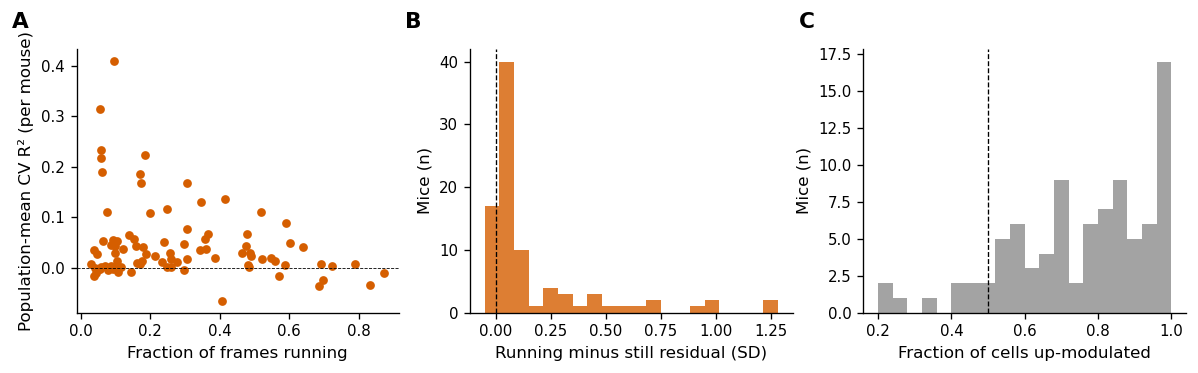

In [20]:
# ---- mouse-level statistics + figure for the running-only analysis ----
by_mouse = run_summary.groupby('mouse')[['r2_cell_median', 'r2_pop', 'delta_median', 'frac_cells_up', 'frac_run']].mean()
n = len(by_mouse)
w1 = stats.wilcoxon(by_mouse.r2_pop)          # is population CV R2 above zero across mice?
w2 = stats.wilcoxon(by_mouse.delta_median)    # is running-minus-still residual different from zero?
print(f'Mice: {n}')
print(f'Population-mean CV R2: median {by_mouse.r2_pop.median():.4f}, Wilcoxon vs 0 p = {w1.pvalue:.3g}')
print(f'Running-minus-still residual (SD units): median {by_mouse.delta_median.median():.4f}, p = {w2.pvalue:.3g}')
print(f'Fraction of cells with higher activity when running: median across mice {by_mouse.frac_cells_up.median():.3f}')
print(f'Sessions individually significant (shuffle p<0.05): {(run_summary.p_null_pop < 0.05).mean():.2f}')

fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
ax[0].scatter(by_mouse.frac_run, by_mouse.r2_pop, s=18, color=COL['run'])
ax[0].axhline(0, color='k', lw=0.5, ls='--')
ax[0].set_xlabel('Fraction of frames running'); ax[0].set_ylabel('Population-mean CV R² (per mouse)')
ax[1].hist(by_mouse.delta_median, bins=20, color=COL['run'], alpha=0.8)
ax[1].axvline(0, color='k', lw=0.8, ls='--')
ax[1].set_xlabel('Running minus still residual (SD)'); ax[1].set_ylabel('Mice (n)')
ax[2].hist(by_mouse.frac_cells_up, bins=20, color=COL['shared'], alpha=0.9)
ax[2].axvline(0.5, color='k', lw=0.8, ls='--')
ax[2].set_xlabel('Fraction of cells up-modulated'); ax[2].set_ylabel('Mice (n)')
for a, l in zip(ax, 'ABC'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig6_running_all_sessions'); plt.show()

In [21]:
import traceback
try:
    load_run_session(boc, 670395999)
except Exception:
    traceback.print_exc()

In [23]:
by_cre = (run_summary.groupby('cre_line')
          .agg(n_mice=('mouse', 'nunique'), pop_r2=('r2_pop', 'median'),
               delta=('delta_median', 'median'), frac_up=('frac_cells_up', 'median'))
          .round(3).sort_values('delta', ascending=False))
print(by_cre)

                   n_mice  pop_r2  delta  frac_up
cre_line                                         
Vip-IRES-Cre            9   0.177  0.728    1.000
Pvalb-IRES-Cre         12   0.063  0.395    1.000
Nr5a1-Cre               4   0.019  0.103    0.771
Emx1-IRES-Cre           4   0.029  0.065    0.799
Scnn1a-Tg3-Cre          5   0.028  0.060    0.713
Slc17a7-IRES2-Cre      12   0.036  0.060    0.844
Rorb-IRES2-Cre          5   0.037  0.054    0.815
Cux2-CreERT2           11   0.039  0.041    0.739
Rbp4-Cre_KL100          6   0.004  0.025    0.695
Sst-IRES-Cre           10   0.003  0.025    0.600
Tlx3-Cre_PL56           3   0.007  0.025    0.558
Fezf2-CreER             3   0.001  0.022    0.677
Ntsr1-Cre_GN220         5   0.004 -0.019    0.429


            n_mice  delta  r2_pop  frac_up
cell_class                                
Excitatory      58  0.050   0.022    0.715
Pvalb           12  0.395   0.063    1.000
Sst             10  0.028   0.006    0.624
Vip              9  0.696   0.217    1.000

Kruskal-Wallis across classes (running-minus-still): H = 39.74, p = 1.21e-08
Pvalb vs Excitatory: Mann-Whitney p = 6.93e-06, Holm-corrected p = 1.39e-05
Sst vs Excitatory: Mann-Whitney p = 0.295, Holm-corrected p = 0.295
Vip vs Excitatory: Mann-Whitney p = 2.4e-06, Holm-corrected p = 7.21e-06
Excitatory: effect vs 0, Wilcoxon p = 1.92e-09 (n = 58 mice)
Pvalb: effect vs 0, Wilcoxon p = 0.000977 (n = 12 mice)
Sst: effect vs 0, Wilcoxon p = 0.00195 (n = 10 mice)
Vip: effect vs 0, Wilcoxon p = 0.00391 (n = 9 mice)


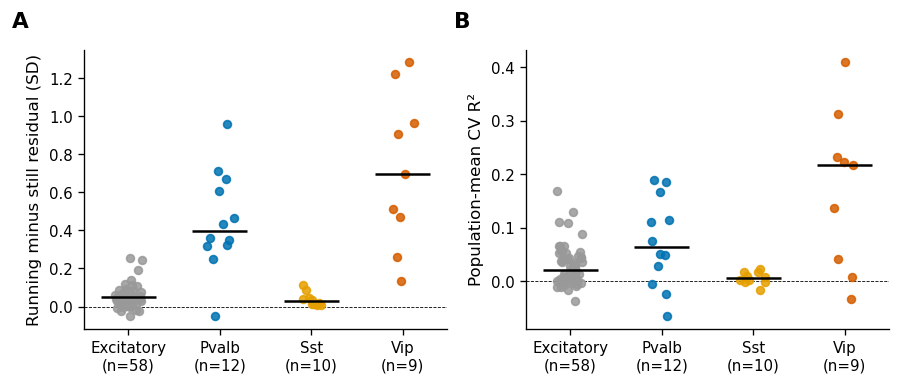

In [24]:
# ---- cell-class comparison of the running effect (mouse-level statistics) ----
def cell_class(cre):
    if cre.startswith('Vip'):   return 'Vip'
    if cre.startswith('Pvalb'): return 'Pvalb'
    if cre.startswith('Sst'):   return 'Sst'
    return 'Excitatory'          # Slc17a7, Emx1, Cux2, Rorb, Scnn1a, Nr5a1, Rbp4, Fezf2, Tlx3, Ntsr1

rs = run_summary.copy()
rs['cell_class'] = rs['cre_line'].astype(str).map(cell_class)
mouse_cls = (rs.groupby(['mouse', 'cell_class'])[['r2_pop', 'delta_median', 'frac_cells_up']]
               .mean().reset_index())                        # one row per mouse x class
order = ['Excitatory', 'Pvalb', 'Sst', 'Vip']
print(mouse_cls.groupby('cell_class').agg(n_mice=('mouse', 'nunique'), delta=('delta_median', 'median'),
      r2_pop=('r2_pop', 'median'), frac_up=('frac_cells_up', 'median')).reindex(order).round(3))

groups_d = [mouse_cls.loc[mouse_cls.cell_class == c, 'delta_median'].values for c in order]
kw = stats.kruskal(*groups_d)
print(f'\nKruskal-Wallis across classes (running-minus-still): H = {kw.statistic:.2f}, p = {kw.pvalue:.3g}')
base = mouse_cls.loc[mouse_cls.cell_class == 'Excitatory', 'delta_median'].values
pvals = {}
for c in order[1:]:
    x = mouse_cls.loc[mouse_cls.cell_class == c, 'delta_median'].values
    pvals[c] = stats.mannwhitneyu(x, base, alternative='two-sided').pvalue
ps = np.array(list(pvals.values())); idx = np.argsort(ps)               # Holm correction
holm = np.empty_like(ps); run_max = 0
for rank, j in enumerate(idx):
    run_max = max(run_max, ps[j] * (len(ps) - rank)); holm[j] = min(1, run_max)
for (c, p), ph in zip(pvals.items(), holm):
    print(f'{c} vs Excitatory: Mann-Whitney p = {p:.3g}, Holm-corrected p = {ph:.3g}')
for c in order:
    x = mouse_cls.loc[mouse_cls.cell_class == c, 'delta_median'].values
    if len(x) >= 5:
        print(f'{c}: effect vs 0, Wilcoxon p = {stats.wilcoxon(x).pvalue:.3g} (n = {len(x)} mice)')

colors = {'Excitatory': '#999999', 'Pvalb': COL['pupil'], 'Sst': '#E69F00', 'Vip': COL['run']}
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.3))
for a, col, lab in zip(ax, ['delta_median', 'r2_pop'],
                       ['Running minus still residual (SD)', 'Population-mean CV R²']):
    for i, c in enumerate(order):
        y = mouse_cls.loc[mouse_cls.cell_class == c, col].values
        a.scatter(i + rng.uniform(-0.15, 0.15, len(y)), y, s=22, color=colors[c], alpha=0.85, zorder=3)
        if len(y): a.hlines(np.median(y), i - 0.3, i + 0.3, color='k', lw=1.5, zorder=4)
    a.axhline(0, color='k', lw=0.5, ls='--')
    a.set_xticks(range(len(order))); a.set_xticklabels([f'{c}\n(n={int((mouse_cls.cell_class==c).sum())})' for c in order])
    a.set_ylabel(lab)
for a, l in zip(ax, 'AB'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig7_cell_classes'); plt.show()

29 sessions to analyse (66 already done)
done 670395999
done 623347352
done 637669270
done 680156911
done 547388708
done 603576132
done 529693740
done 584196534
done 593373156
done 595263154
done 508356957
done 675477919
done 712178511
done 692345003
done 657082055
done 673914981
done 559192380
done 658536111
done 647155122
done 670728674
done 662974315
done 609894681
done 502115959
done 592407200
done 645086975
done 502608215
done 657775947
done 637115675
done 627823695


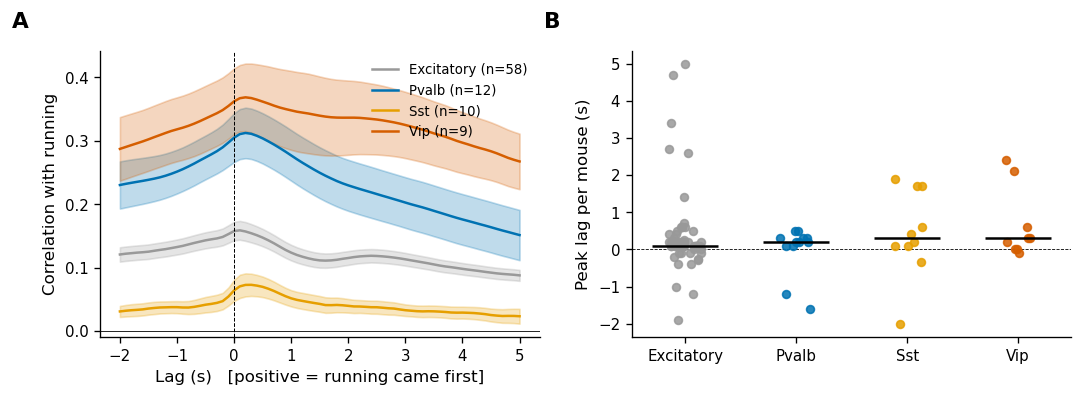

            count  median
cell_class               
Excitatory     58     0.1
Pvalb          12     0.2
Sst            10     0.3
Vip             9     0.3
Kruskal-Wallis on peak lag across classes: p = 0.634
Mean correlation at lags <= -1 s (neural activity BEFORE running; should be near 0): 0.1467
Mean correlation at the peak: 0.2008


In [25]:
# ---- TIMING: lag between running and population residual activity ----
LAG_FR = np.arange(-60, 151, 3)            # frames at ~30 Hz: -2 s ... +5 s (positive = running came first)
FS_NOMINAL = 30.0

def cell_class(cre):
    if cre.startswith('Vip'):   return 'Vip'
    if cre.startswith('Pvalb'): return 'Pvalb'
    if cre.startswith('Sst'):   return 'Sst'
    return 'Excitatory'

def timing_session(sess):
    t = sess['t']; fs = 1.0 / np.median(np.diff(t))
    spd = smooth(sess['run'], 0.2, fs)
    lr = np.log1p(np.clip(spd, 0, None))
    z = np.clip((lr - lr.mean()) / (lr.std() + 1e-12), -5, 5)
    Y, B, ok = build_tensors(sess, {'run': z, '_t': t - t[0]})
    n_cells, n_rep, n_fr = Y.shape
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S)
    if valid.sum() < MIN_VALID: raise ValueError('too few usable frames')
    frac = float(np.mean(_run_at(sess, ok)[valid] > RUN_THR))
    if not (FRAC_RUN_RANGE[0] <= frac <= FRAC_RUN_RANGE[1]):
        raise ValueError(f'running fraction {frac:.3f} outside range')
    mu = Yres[:, valid].mean(1)[:, None, None]; sd = Yres[:, valid].std(1)[:, None, None] + 1e-9
    pm = np.nanmean((Yres - mu) / sd, axis=0)                 # population-mean residual on the (repeat, frame) grid
    a = pm[valid]; a = (a - a.mean()) / (a.std() + 1e-12)
    corr = np.array([np.corrcoef(a, shift2d(B['run'], int(k))[valid])[0, 1] for k in LAG_FR])
    return corr

import pickle
TIM_PKL = 'timing_curves.pkl'
curves = pickle.load(open(TIM_PKL, 'rb')) if os.path.exists(TIM_PKL) else {}
todo_t = run_summary[~run_summary.exp_id.isin(curves.keys())]
print(f'{len(todo_t)} sessions to analyse ({len(curves)} already done)')
for k, (_, r) in enumerate(todo_t.iterrows()):
    try:
        curves[r['exp_id']] = timing_session(load_run_session(boc, r['exp_id']))
        print('done', r['exp_id'])
    except Exception as e:
        print('skipped', r['exp_id'], '->', repr(e))
    if (k + 1) % 10 == 0:
        pickle.dump(curves, open(TIM_PKL, 'wb'))
pickle.dump(curves, open(TIM_PKL, 'wb'))

# ---- summarise by cell class, mouse-level ----
lag_s = LAG_FR / FS_NOMINAL
tm = run_summary[run_summary.exp_id.isin(curves.keys())].copy()
tm['cell_class'] = tm['cre_line'].astype(str).map(cell_class)
C = np.stack([curves[e] for e in tm.exp_id])
tm['peak_lag_s'] = lag_s[np.nanargmax(C, axis=1)]
tm['peak_r'] = C.max(1)
order = ['Excitatory', 'Pvalb', 'Sst', 'Vip']
colors = {'Excitatory': '#999999', 'Pvalb': COL['pupil'], 'Sst': '#E69F00', 'Vip': COL['run']}

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for c in order:
    idx = np.where(tm.cell_class.values == c)[0]
    if len(idx) == 0: continue
    cm = pd.DataFrame(C[idx]); cm['mouse'] = tm.mouse.values[idx]
    mm = cm.groupby('mouse').mean().to_numpy()               # one curve per mouse
    m, s = mm.mean(0), mm.std(0) / np.sqrt(len(mm))
    ax[0].plot(lag_s, m, color=colors[c], label=f'{c} (n={len(mm)})')
    ax[0].fill_between(lag_s, m - s, m + s, color=colors[c], alpha=0.25)
ax[0].axvline(0, color='k', lw=0.6, ls='--'); ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_xlabel('Lag (s)   [positive = running came first]'); ax[0].set_ylabel('Correlation with running')
ax[0].legend()
mouse_peak = tm.groupby(['mouse', 'cell_class'])['peak_lag_s'].mean().reset_index()
for i, c in enumerate(order):
    y = mouse_peak.loc[mouse_peak.cell_class == c, 'peak_lag_s'].values
    ax[1].scatter(i + rng.uniform(-0.15, 0.15, len(y)), y, s=22, color=colors[c], alpha=0.85, zorder=3)
    if len(y): ax[1].hlines(np.median(y), i - 0.3, i + 0.3, color='k', lw=1.5, zorder=4)
ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order)
ax[1].set_ylabel('Peak lag per mouse (s)'); ax[1].axhline(0, color='k', lw=0.5, ls='--')
for a, l in zip(ax, 'AB'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig8_timing'); plt.show()

print(mouse_peak.groupby('cell_class')['peak_lag_s'].agg(['count', 'median']).reindex(order).round(2))
kw = stats.kruskal(*[mouse_peak.loc[mouse_peak.cell_class == c, 'peak_lag_s'].values for c in order])
print(f'Kruskal-Wallis on peak lag across classes: p = {kw.pvalue:.3g}')
neg = lag_s <= -1.0
print('Mean correlation at lags <= -1 s (neural activity BEFORE running; should be near 0):', round(float(C[:, neg].mean()), 4))
print('Mean correlation at the peak:', round(float(tm.peak_r.mean()), 4))

29 sessions to analyse (66 already done)
done 670395999
done 623347352
done 637669270
done 680156911
done 547388708
done 603576132
done 529693740
done 584196534
done 593373156
done 595263154
skipped 508356957 -> ValueError('only 0 clean onsets')
done 675477919
done 712178511
done 692345003
done 657082055
done 673914981
done 559192380
done 658536111
done 647155122
done 670728674
done 662974315
done 609894681
skipped 502115959 -> ValueError('only 0 clean onsets')
done 592407200
done 645086975
done 502608215
done 657775947
done 637115675
done 627823695


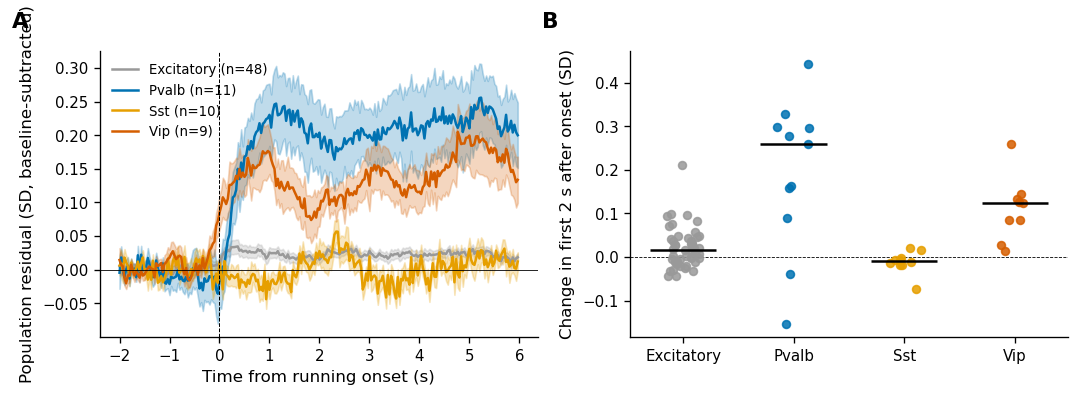

84 sessions with enough onsets (median 43 onsets each); 11 dropped
Excitatory (n=48 mice): rise after onset median 0.017 SD, Wilcoxon p = 0.0034 | pre-onset change (-1..0 s vs -2..-1 s) median -0.002, p = 0.803
Pvalb (n=11 mice): rise after onset median 0.259 SD, Wilcoxon p = 0.00684 | pre-onset change (-1..0 s vs -2..-1 s) median 0.001, p = 0.765
Sst (n=10 mice): rise after onset median -0.010 SD, Wilcoxon p = 0.232 | pre-onset change (-1..0 s vs -2..-1 s) median 0.016, p = 0.846
Vip (n=9 mice): rise after onset median 0.124 SD, Wilcoxon p = 0.00391 | pre-onset change (-1..0 s vs -2..-1 s) median 0.027, p = 0.426


In [26]:
# ---- TIMING 2: running-onset-triggered population residual (sharper than correlation lags) ----
PRE, POST, MIN_ONSETS = 60, 180, 5          # frames (~2 s before, ~6 s after); sessions need >= 5 clean onsets

def onset_session(sess):
    t = sess['t']; fs = 1.0 / np.median(np.diff(t))
    spd = smooth(sess['run'], 0.2, fs)
    lr = np.log1p(np.clip(spd, 0, None))
    z = np.clip((lr - lr.mean()) / (lr.std() + 1e-12), -5, 5)
    Y, B, ok = build_tensors(sess, {'run': z, '_t': t - t[0]})
    n_cells, n_rep, n_fr = Y.shape
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S)
    if valid.sum() < MIN_VALID: raise ValueError('too few usable frames')
    mu = np.nanmean(np.where(valid, Yres, np.nan), axis=(1, 2))[:, None, None]
    sd = np.nanstd(np.where(valid, Yres, np.nan), axis=(1, 2))[:, None, None] + 1e-9
    pm = np.nanmean((Yres - mu) / sd, axis=0)
    pm[~valid] = np.nan                                         # population-mean residual on (repeat, frame) grid
    run_grid = _run_at(sess, ok)
    segs = []
    for r in range(n_rep):
        for o in find_run_onsets(np.nan_to_num(run_grid[r]), fs):
            if o - PRE >= 0 and o + POST <= n_fr:
                seg = pm[r, o - PRE:o + POST]
                if np.isfinite(seg).mean() > 0.9:
                    segs.append(seg - np.nanmean(seg[:30]))     # baseline = first second of the window
    if len(segs) < MIN_ONSETS: raise ValueError(f'only {len(segs)} clean onsets')
    return np.nanmean(np.array(segs), axis=0), len(segs)

import pickle
ONS_PKL = 'onset_curves.pkl'
ons = pickle.load(open(ONS_PKL, 'rb')) if os.path.exists(ONS_PKL) else {}
todo_o = run_summary[~run_summary.exp_id.isin(ons.keys())]
print(f'{len(todo_o)} sessions to analyse ({len(ons)} already done)')
for k, (_, r) in enumerate(todo_o.iterrows()):
    try:
        ons[r['exp_id']] = onset_session(load_run_session(boc, r['exp_id'])); print('done', r['exp_id'])
    except Exception as e:
        ons[r['exp_id']] = None; print('skipped', r['exp_id'], '->', repr(e))
    if (k + 1) % 10 == 0: pickle.dump(ons, open(ONS_PKL, 'wb'))
pickle.dump(ons, open(ONS_PKL, 'wb'))

good = run_summary[run_summary.exp_id.map(lambda e: ons.get(e) is not None)].copy()
good['cell_class'] = good['cre_line'].astype(str).map(cell_class)
good['curve'] = [ons[e][0] for e in good.exp_id]; good['n_ons'] = [ons[e][1] for e in good.exp_id]
tau = np.arange(-PRE, POST) / FS_NOMINAL
order = ['Excitatory', 'Pvalb', 'Sst', 'Vip']
colors = {'Excitatory': '#999999', 'Pvalb': COL['pupil'], 'Sst': '#E69F00', 'Vip': COL['run']}
pre_w = (tau >= -1) & (tau < 0); early = (tau >= 0) & (tau < 2); late = (tau >= 2) & (tau < 6); p1 = (tau >= -2) & (tau < -1)

mouse_c = {}
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for c in order:
    g = good[good.cell_class == c]
    if g.empty: continue
    mc = pd.DataFrame(np.stack(g.curve.values)); mc['mouse'] = g.mouse.values
    mm = mc.groupby('mouse').mean().to_numpy(); mouse_c[c] = mm
    m, s = mm.mean(0), mm.std(0) / np.sqrt(len(mm))
    ax[0].plot(tau, m, color=colors[c], label=f'{c} (n={len(mm)})'); ax[0].fill_between(tau, m - s, m + s, color=colors[c], alpha=0.25)
ax[0].axvline(0, color='k', lw=0.6, ls='--'); ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_xlabel('Time from running onset (s)'); ax[0].set_ylabel('Population residual (SD, baseline-subtracted)'); ax[0].legend()
for i, c in enumerate(order):
    if c not in mouse_c: continue
    y = mouse_c[c][:, early].mean(1) - mouse_c[c][:, pre_w].mean(1)
    ax[1].scatter(i + rng.uniform(-0.15, 0.15, len(y)), y, s=22, color=colors[c], alpha=0.85, zorder=3)
    ax[1].hlines(np.median(y), i - 0.3, i + 0.3, color='k', lw=1.5, zorder=4)
ax[1].axhline(0, color='k', lw=0.5, ls='--'); ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order)
ax[1].set_ylabel('Change in first 2 s after onset (SD)')
for a, l in zip(ax, 'AB'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig9_onset_triggered'); plt.show()

print(f'{len(good)} sessions with enough onsets (median {int(good.n_ons.median())} onsets each); {len(run_summary)-len(good)} dropped')
for c in order:
    if c not in mouse_c or len(mouse_c[c]) < 5: continue
    mm = mouse_c[c]
    inc = mm[:, early].mean(1) - mm[:, pre_w].mean(1)
    pre_slope = mm[:, pre_w].mean(1) - mm[:, p1].mean(1)
    print(f'{c} (n={len(mm)} mice): rise after onset median {np.median(inc):.3f} SD, Wilcoxon p = {stats.wilcoxon(inc).pvalue:.3g} | '
          f'pre-onset change (-1..0 s vs -2..-1 s) median {np.median(pre_slope):.3f}, p = {stats.wilcoxon(pre_slope).pvalue:.3g}')

In [27]:
for c in ['Excitatory', 'Pvalb', 'Sst', 'Vip']:
    if c in mouse_c and len(mouse_c[c]) >= 5:
        mm = mouse_c[c]
        late_inc = mm[:, late].mean(1) - mm[:, pre_w].mean(1)
        print(f'{c}: change 2-6 s after onset median {np.median(late_inc):.3f} SD, '
              f'Wilcoxon p = {stats.wilcoxon(late_inc).pvalue:.3g}')
inc_v = mouse_c['Vip'][:, early].mean(1) - mouse_c['Vip'][:, pre_w].mean(1)
inc_e = mouse_c['Excitatory'][:, early].mean(1) - mouse_c['Excitatory'][:, pre_w].mean(1)
print('Vip vs Excitatory early rise: Mann-Whitney p =', stats.mannwhitneyu(inc_v, inc_e).pvalue)

Excitatory: change 2-6 s after onset median 0.021 SD, Wilcoxon p = 2.45e-05
Pvalb: change 2-6 s after onset median 0.227 SD, Wilcoxon p = 0.00977
Sst: change 2-6 s after onset median 0.000 SD, Wilcoxon p = 0.77
Vip: change 2-6 s after onset median 0.153 SD, Wilcoxon p = 0.00391
Vip vs Excitatory early rise: Mann-Whitney p = 0.0005230253976576715


8 pupil sessions to analyse
done 528402271
done 581150104
done 502962794
done 571137446
done 501729039
done 580163817
done 570278597
done 559192380
   exp_id       cre_line  n_valid  frac_run  pupil_missing  corr_run_pupil  r2_run  r2_pupil  r2_both  uniq_run  uniq_pupil  shared  arousal_beyond_run  p_null_arousal
528402271  Emx1-IRES-Cre     9745     0.119          0.479           0.814  -0.032     0.011    0.002    -0.009       0.034  -0.023               0.003           0.137
581150104   Sst-IRES-Cre    32510     0.207          0.053           0.513   0.023     0.012    0.027     0.015       0.004   0.008               0.002           0.176
502962794 Rbp4-Cre_KL100    23278     0.054          0.156           0.035  -0.008    -0.008   -0.006     0.001       0.002  -0.010               0.002           0.176
571137446 Rbp4-Cre_KL100    32268     0.267          0.045           0.764   0.001     0.021    0.022     0.001       0.021  -0.000               0.031           0.020
501729039 Ro

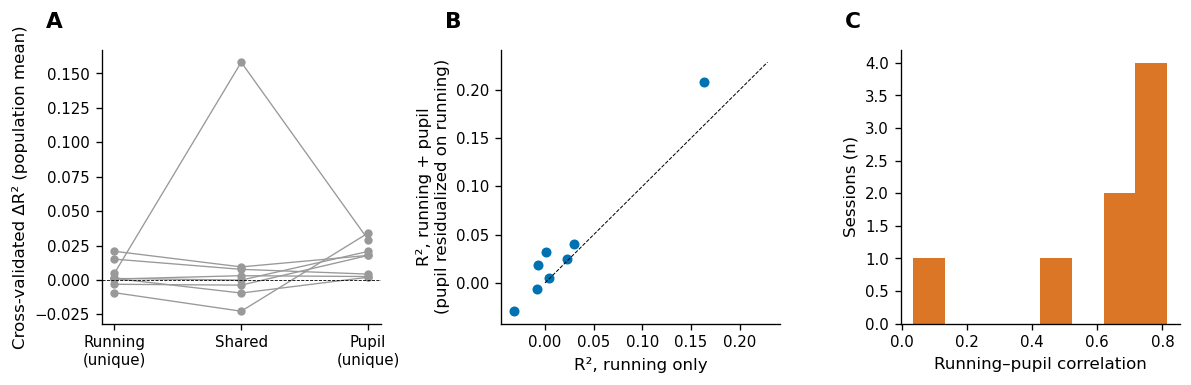

In [28]:
# ===== PUPIL ANALYSIS on sessions with eye tracking AND usable running =====
def clean_pupil_log(area, fs, max_gap_s=0.5):
    a = np.asarray(area, float).copy()
    a[a <= 0] = np.nan
    lo, hi = np.nanpercentile(a, [0.5, 99.5])         # gentler clip than before (keeps real dilations)
    a = np.log(np.clip(a, lo, hi))                    # log area is better behaved than raw area
    a = fill_short_gaps(a, int(max_gap_s * fs))       # only short gaps are filled; long gaps stay NaN
    return a, float(np.mean(~np.isfinite(a)))

def load_pupil_session(boc, exp_id, stim=STIM):
    ds = boc.get_ophys_experiment_data(int(exp_id))
    t, dff = ds.get_dff_traces()
    dxcm, dxt = ds.get_running_speed()
    run = _interp_valid(t, dxt, dxcm)
    pt, pa = ds.get_pupil_size()
    pa_c, miss = clean_pupil_log(pa, 1.0 / np.median(np.diff(pt)))
    st = ds.get_stimulus_table(stim).copy()
    if 'repeat' not in st.columns:
        st['repeat'] = (st['frame'] == 0).cumsum() - 1
    return dict(exp_id=exp_id, t=np.asarray(t), dff=np.asarray(dff), run=run,
                pupil=np.interp(t, pt, pa_c), pupil_missing=miss, stim_table=st)

def analyze_pupil(sess, n_perm=50, alpha=1e4):
    feats, fs = behavior_features(sess)
    Y, B, ok = build_tensors(sess, feats)
    n_cells, n_rep, n_fr = Y.shape
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo
    designs_full = {k: make_design(B, v['names'], v['interaction']) for k, v in MODEL_SETS.items()}
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S)
    for D in designs_full.values():
        valid &= np.isfinite(D).all(-1)
    if valid.sum() < MIN_VALID: raise ValueError(f'only {valid.sum()} usable frames')
    frac_run = float(np.mean(_run_at(sess, ok)[valid] > RUN_THR))
    if frac_run < 0.01: raise ValueError(f'mouse ran only {100*frac_run:.2f}% of pupil-valid frames')

    groups = np.broadcast_to(np.arange(n_rep)[:, None], (n_rep, n_fr))[valid]
    Rraw = Yres[:, valid].T
    R = (Rraw - Rraw.mean(0)) / (Rraw.std(0) + 1e-9)
    pm = R.mean(1, keepdims=True); pm = (pm - pm.mean()) / (pm.std() + 1e-12)   # population-mean residual
    X = {k: D[valid] for k, D in designs_full.items()}
    r2 = {k: float(cv_r2(pm, X[k], groups, alpha)[0]) for k in X}

    # null for "arousal beyond running": shift ONLY the pupil-residual columns, keep running intact
    nr = len(LAGS); obs = r2['run+pupilR'] - r2['run']; null = []
    for _ in range(n_perm):
        k = rng.integers(300, len(pm) - 300)
        Xs = X['run+pupilR'].copy(); Xs[:, nr:] = np.roll(Xs[:, nr:], k, axis=0)
        null.append(float(cv_r2(pm, Xs, groups, alpha)[0]) - r2['run'])
    p_null = (1 + (np.array(null) >= obs).sum()) / (n_perm + 1)
    return dict(n_cells=n_cells, n_valid=int(valid.sum()), frac_run=frac_run, pupil_missing=sess['pupil_missing'],
                corr_run_pupil=float(np.corrcoef(B['run'][valid], B['pupil'][valid])[0, 1]),
                r2_run=r2['run'], r2_pupil=r2['pupil'], r2_both=r2['both'], r2_run_pupilR=r2['run+pupilR'],
                uniq_run=r2['both'] - r2['pupil'], uniq_pupil=r2['both'] - r2['run'],
                shared=r2['run'] + r2['pupil'] - r2['both'],
                arousal_beyond_run=obs, p_null_arousal=float(p_null))

pup_todo = bs[(bs.has_pupil == True) & (bs.frac_run_in_movie > 0.02) & (bs.frac_run_in_movie < 0.95)]
print(len(pup_todo), 'pupil sessions to analyse')
prow = []
for _, r in pup_todo.iterrows():
    try:
        out = analyze_pupil(load_pupil_session(boc, r['exp_id']))
        out.update(exp_id=r['exp_id'], mouse=r['mouse'], cre_line=r['cre_line'])
        prow.append(out); print('done', r['exp_id'])
    except Exception as e:
        print('skipped', r['exp_id'], '->', repr(e))
pup_df = pd.DataFrame(prow); pup_df.to_csv('pupil_summary.csv', index=False)
cols = ['exp_id', 'cre_line', 'n_valid', 'frac_run', 'pupil_missing', 'corr_run_pupil',
        'r2_run', 'r2_pupil', 'r2_both', 'uniq_run', 'uniq_pupil', 'shared', 'arousal_beyond_run', 'p_null_arousal']
print(pup_df[cols].round(3).to_string(index=False))

pm_ = pup_df.groupby('mouse')[['uniq_run', 'uniq_pupil', 'shared', 'arousal_beyond_run', 'corr_run_pupil']].mean()
print(f'\n{len(pm_)} mice')
print(f'Unique running: median {pm_.uniq_run.median():.4f} | unique pupil: median {pm_.uniq_pupil.median():.4f} | shared: median {pm_.shared.median():.4f}')
if len(pm_) >= 5:
    print('Unique pupil vs 0, Wilcoxon p =', stats.wilcoxon(pm_.uniq_pupil).pvalue)
    print('Arousal beyond running vs 0, Wilcoxon p =', stats.wilcoxon(pm_.arousal_beyond_run).pvalue)
print('Median run-pupil correlation:', round(float(pm_.corr_run_pupil.median()), 3))

fig, ax = plt.subplots(1, 3, figsize=(10, 3.3))
for _, r in pup_df.iterrows():
    ax[0].plot([0, 1, 2], [r.uniq_run, r.shared, r.uniq_pupil], color='#999999', lw=0.8, marker='o', ms=4)
ax[0].set_xticks([0, 1, 2]); ax[0].set_xticklabels(['Running\n(unique)', 'Shared', 'Pupil\n(unique)'])
ax[0].axhline(0, color='k', lw=0.5, ls='--'); ax[0].set_ylabel('Cross-validated ΔR² (population mean)')
ax[1].scatter(pup_df.r2_run, pup_df.r2_run_pupilR, s=25, color=COL['pupil'])
lim = max(pup_df.r2_run.max(), pup_df.r2_run_pupilR.max()) * 1.1
ax[1].plot([0, lim], [0, lim], 'k--', lw=0.6)
ax[1].set_xlabel('R², running only'); ax[1].set_ylabel('R², running + pupil\n(pupil residualized on running)')
ax[2].hist(pup_df.corr_run_pupil, bins=8, color=COL['run'], alpha=0.85)
ax[2].set_xlabel('Running–pupil correlation'); ax[2].set_ylabel('Sessions (n)')
for a, l in zip(ax, 'ABC'): panel_label(a, l)
fig.tight_layout(); save_fig(fig, 'fig10_pupil'); plt.show()

In [29]:
# ===== STRICTER PUPIL CONTROL: remove movie-locked pupil (light reflex) + 500 shuffles =====
import warnings

def analyze_pupil2(sess, n_perm=500, alpha=1e4, remove_stim_locked=True):
    feats, fs = behavior_features(sess)
    Y, B, ok = build_tensors(sess, feats)
    n_cells, n_rep, n_fr = Y.shape
    if remove_stim_locked:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for name in ('pupil', 'dpupil', 'pupil_resid'):
                P = B[name]                                   # (repeat, frame); subtract mean of the OTHER repeats
                loo_p = np.stack([np.nanmean(np.delete(P, r, axis=0), axis=0) for r in range(n_rep)], axis=0)
                B[name] = P - loo_p
    loo = np.stack([np.nanmean(np.delete(Y, r, axis=1), axis=1) for r in range(n_rep)], axis=1)
    Yres = Y - loo
    designs_full = {k: make_design(B, v['names'], v['interaction']) for k, v in MODEL_SETS.items()}
    valid = ok & np.isfinite(Yres).all(0) & (B['_t'] > DROP_FIRST_S)
    for D in designs_full.values():
        valid &= np.isfinite(D).all(-1)
    if valid.sum() < MIN_VALID: raise ValueError(f'only {valid.sum()} usable frames')
    frac_run = float(np.mean(_run_at(sess, ok)[valid] > RUN_THR))
    if frac_run < 0.01: raise ValueError(f'mouse ran only {100*frac_run:.2f}% of pupil-valid frames')

    groups = np.broadcast_to(np.arange(n_rep)[:, None], (n_rep, n_fr))[valid]
    Rraw = Yres[:, valid].T
    R = (Rraw - Rraw.mean(0)) / (Rraw.std(0) + 1e-9)
    pm = R.mean(1, keepdims=True); pm = (pm - pm.mean()) / (pm.std() + 1e-12)
    X = {k: D[valid] for k, D in designs_full.items()}
    r2 = {k: float(cv_r2(pm, X[k], groups, alpha)[0]) for k in X}

    nr = len(LAGS); obs = r2['run+pupilR'] - r2['run']; null = []
    for _ in range(n_perm):
        k = rng.integers(300, len(pm) - 300)
        Xs = X['run+pupilR'].copy(); Xs[:, nr:] = np.roll(Xs[:, nr:], k, axis=0)
        null.append(float(cv_r2(pm, Xs, groups, alpha)[0]) - r2['run'])
    p_null = (1 + (np.array(null) >= obs).sum()) / (n_perm + 1)
    return dict(n_valid=int(valid.sum()), corr_run_pupil=float(np.corrcoef(B['run'][valid], B['pupil'][valid])[0, 1]),
                r2_run=r2['run'], r2_both=r2['both'], uniq_run=r2['both'] - r2['pupil'],
                uniq_pupil=r2['both'] - r2['run'], arousal_beyond_run=obs, p_null_arousal=float(p_null))

N_PERM = 500
rows2 = []
for _, r in pup_todo.iterrows():
    try:
        sess_p = load_pupil_session(boc, r['exp_id'])
        for label, flag in (('original', False), ('strict', True)):
            out = analyze_pupil2(sess_p, n_perm=N_PERM, remove_stim_locked=flag)
            out.update(exp_id=r['exp_id'], mouse=r['mouse'], cre_line=r['cre_line'], version=label)
            rows2.append(out)
        print('done', r['exp_id'])
    except Exception as e:
        print('skipped', r['exp_id'], '->', repr(e))
p2 = pd.DataFrame(rows2); p2.to_csv('pupil_strict_summary.csv', index=False)

wide = p2.pivot(index='exp_id', columns='version', values=['uniq_pupil', 'arousal_beyond_run', 'p_null_arousal', 'corr_run_pupil']).round(4)
print(wide.to_string())
for v in ('original', 'strict'):
    d = p2[p2.version == v].groupby('mouse')[['uniq_pupil', 'arousal_beyond_run']].mean()
    pos = int((d.arousal_beyond_run > 0).sum())
    print(f"\n[{v}] {len(d)} mice | unique pupil median {d.uniq_pupil.median():.4f} | arousal beyond running median "
          f"{d.arousal_beyond_run.median():.4f} | positive in {pos}/{len(d)} | Wilcoxon p = {stats.wilcoxon(d.arousal_beyond_run).pvalue:.3g}")
    s = p2[p2.version == v]
    print(f"[{v}] sessions individually significant (shuffle p < 0.05): {(s.p_null_arousal < 0.05).sum()}/{len(s)}")

done 528402271
done 581150104
done 502962794
done 571137446
done 501729039
done 580163817
done 570278597
done 559192380
          uniq_pupil         arousal_beyond_run         p_null_arousal         corr_run_pupil        
version     original  strict           original  strict       original  strict       original  strict
exp_id                                                                                               
501729039     0.0178  0.0188             0.0097  0.0096         0.0020  0.0020         0.6617  0.6549
502962794     0.0020  0.0010             0.0018  0.0007         0.1717  0.3972         0.0350  0.0346
528402271     0.0340  0.0183             0.0027  0.0037         0.1537  0.0559         0.8136  0.7588
559192380     0.0178  0.0219             0.0257  0.0284         0.0020  0.0020         0.6376  0.6107
570278597     0.0294  0.0136             0.0447  0.0433         0.0020  0.0020         0.7776  0.7598
571137446     0.0207  0.0231             0.0312  0.0341         